## Đồ Án 2

## Import data
Lưu ý: Tọa độ thành phố Hồ Chí Minh chỉ từ 10.38-11.10 vĩ độ bắc và 106.22-106.56 kinh độ đông

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import numpy as np



In [54]:
DATASET_PATH = "./data/price_training.csv"  # Path to your dataset

### (Tuỳ chọn) Tạo dữ liệu huấn luyện từ database
Chuyển dữ liệu thô trong bảng `listings` thành CSV có đúng các cột `loại nhà đất, địa chỉ, giá, diện tích, giá/m2, mặt tiền, phòng ngủ, pháp lý, tọa độ x, tọa độ y, số tầng` bằng `db_to_training/build_training_csv.py`.
Đặt `BUILD_FROM_DB = True` rồi chạy ô dưới (cần Postgres đang chạy và `PGPASSWORD`); ô sẽ ghi `data/price_training_db.csv` và dùng nó làm `DATASET_PATH`. Mặc định giữ nguyên `price_training.csv`.

In [ ]:
BUILD_FROM_DB = False  # True: tạo CSV huấn luyện từ database rồi dùng nó thay cho price_training.csv
DB_URL = "postgresql://postgres:<mật khẩu>@localhost:5432/housing_dev"

if BUILD_FROM_DB:
    import sys
    sys.path.append("./db_to_training")
    from pathlib import Path
    from build_training_csv import TrainingCsvBuilder

    DATASET_PATH = "./data/price_training_db.csv"
    TrainingCsvBuilder(DB_URL, Path(DATASET_PATH)).run()


In [55]:
df = pd.read_csv(DATASET_PATH)


In [56]:
df.shape

(43025, 11)

In [57]:
# Lọc trùng lặp
df = df.drop_duplicates()
df.shape

(18155, 11)

In [58]:
# Bởi vì data tạo độ lúc crawl có nhân 1 tỷ nên cần chia lại cho đúng
df["tọa độ x"], df["tọa độ y"] = df["tọa độ x"]/1000000000, df["tọa độ y"]/1000000000
df.drop(columns=["giá"], inplace=True)

C:\Users\huypro37\AppData\Local\Temp\ipykernel_21104\734308156.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["giá"], inplace=True)


Thêm khoảng cách từ vị trí bất động sản để trung tâm thành phố, là vị trí của nhà thờ Đức Bà (lat:10.7769, lon:106.7009)

In [59]:
lat = 10.7769
lon = 106.7009

def haversine(lat1, lon1, lat2, lon2):
    R = 6371

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat/2)**2 + \
        np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2

    c = 2*np.arcsin(np.sqrt(a))

    return R*c

df["cách trung tâm"] = haversine(
    df["tọa độ x"],
    df["tọa độ y"],
    lat,
    lon
)

In [60]:
from pathlib import Path
from pipeline import dem_tien_ich

# Đặc trưng tiện ích: số POI trong bán kính r km quanh bất động sản (đếm bằng PostGIS).
# Chỉ truy vấn DB lần đầu, sau đó đọc cache. Đặt FORCE_RECOMPUTE = True để tính lại.
FORCE_RECOMPUTE = False
POI_CACHE = Path("./data/poi_features.csv")
POI_RADII_KM = [0.5, 1, 2, 3, 5]
# tên nhóm: (bảng POI, điều kiện lọc). ownership thật trong DB: 'Công lập' | 'Ngoài công lập'
POI_GROUPS = {
    "trường học":            ("amenities.poi_schools", None),
    "trường công lập":       ("amenities.poi_schools", {"ownership": "Công lập"}),
    "trường ngoài công lập": ("amenities.poi_schools", {"ownership": "Ngoài công lập"}),
    "bệnh viện":             ("amenities.poi_hospitals", {"poi_subtype": "Bệnh viện"}),
    "chợ":                   ("amenities.poi_markets", None),
}
POI_COLS = [f"{g} {r} km" for g in POI_GROUPS for r in POI_RADII_KM]

poi_features = None
if POI_CACHE.exists() and not FORCE_RECOMPUTE:
    poi_features = pd.read_csv(POI_CACHE, index_col=0)
    if not (set(POI_COLS) <= set(poi_features.columns) and df.index.isin(poi_features.index).all()):
        poi_features = None  # cache cũ/thiếu -> tính lại
if poi_features is None:
    poi_features = pd.DataFrame(index=df.index)
    for g, (bang, dieu_kien) in POI_GROUPS.items():
        for r in POI_RADII_KM:
            poi_features[f"{g} {r} km"] = dem_tien_ich(df, bang, r, dieu_kien)
    POI_CACHE.parent.mkdir(exist_ok=True)
    poi_features.to_csv(POI_CACHE)
df[POI_COLS] = poi_features.loc[df.index, POI_COLS]

In [61]:
df.head()

,loại nhà đất,địa chỉ,diện tích,giá/m2,mặt tiền,phòng ngủ,pháp lý,tọa độ x,tọa độ y,số tầng,...,bệnh viện 0.5 km,bệnh viện 1 km,bệnh viện 2 km,bệnh viện 3 km,bệnh viện 5 km,chợ 0.5 km,chợ 1 km,chợ 2 km,chợ 3 km,chợ 5 km
0,0,23,88.8,73.09,NaN,2.0,NaN,10.803385,106.617524,NaN,...,0.0,0.0,1.0,3.0,10.0,0.0,1.0,2.0,10.0,28.0
1,2,5,47.0,92.55,4.0,2.0,1.0,10.842744,106.642948,2.0,...,0.0,0.0,0.0,3.0,6.0,1.0,1.0,3.0,7.0,20.0
2,7,21,216.0,82.87,12.0,NaN,1.0,10.842596,106.717190,NaN,...,0.0,1.0,1.0,2.0,9.0,0.0,0.0,2.0,4.0,19.0
3,0,18,65.0,76.92,NaN,2.0,2.0,10.750351,106.723175,NaN,...,0.0,1.0,5.0,14.0,36.0,0.0,3.0,11.0,15.0,28.0
4,4,0,128.0,58.59,6.0,5.0,1.0,10.669288,106.613250,3.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,2.0,2.0,8.0


In [62]:
df.info()

<class 'pandas.DataFrame'>
Index: 18155 entries, 0 to 43024
Data columns (total 36 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   loại nhà đất                  18155 non-null  int64  
 1   địa chỉ                       18155 non-null  int64  
 2   diện tích                     18155 non-null  float64
 3   giá/m2                        18155 non-null  float64
 4   mặt tiền                      10644 non-null  float64
 5   phòng ngủ                     12441 non-null  float64
 6   pháp lý                       14904 non-null  float64
 7   tọa độ x                      18155 non-null  float64
 8   tọa độ y                      18155 non-null  float64
 9   số tầng                       8279 non-null   float64
 10  cách trung tâm                18155 non-null  float64
 11  trường học 0.5 km             18155 non-null  float64
 12  trường học 1 km               18155 non-null  float64
 13  trường học 2 km  

In [63]:
df.describe()

,loại nhà đất,địa chỉ,diện tích,giá/m2,mặt tiền,phòng ngủ,pháp lý,tọa độ x,tọa độ y,số tầng,...,bệnh viện 0.5 km,bệnh viện 1 km,bệnh viện 2 km,bệnh viện 3 km,bệnh viện 5 km,chợ 0.5 km,chợ 1 km,chợ 2 km,chợ 3 km,chợ 5 km
count,18155.000000,18155.000000,18155.000000,18155.000000,10644.000000,12441.000000,14904.000000,18155.000000,18155.000000,8279.000000,...,18155.000000,18155.000000,18155.000000,18155.000000,18155.000000,18155.000000,18155.000000,18155.000000,18155.000000,18155.000000
mean,2.482787,13.137097,116.008473,144.652577,7.188966,3.811591,1.120035,11.005535,106.630561,3.536659,...,0.399890,1.520022,5.886918,12.455632,30.517598,0.358469,1.413715,5.510052,11.888240,30.525530
std,2.215867,7.150716,107.577203,275.763564,18.201371,4.621149,0.325013,1.501373,2.306344,1.716379,...,0.953727,2.716645,8.979377,16.829012,30.704462,0.598881,1.561906,4.774633,9.573764,20.884822
min,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,7.000000,60.000000,69.590000,4.000000,2.000000,1.000000,10.762441,106.654216,2.000000,...,0.000000,0.000000,1.000000,2.000000,6.000000,0.000000,0.000000,2.000000,5.000000,15.000000
50%,2.000000,13.000000,82.800000,108.180000,5.000000,3.000000,1.000000,10.793171,106.697893,3.000000,...,0.000000,0.000000,2.000000,5.000000,14.000000,0.000000,1.000000,4.000000,8.000000,23.000000
75%,4.000000,20.000000,126.000000,171.130000,7.000000,4.000000,1.000000,10.826613,106.736489,4.000000,...,0.000000,2.000000,7.000000,14.000000,52.000000,1.000000,2.000000,8.000000,18.000000,46.000000
max,7.000000,23.000000,996.000000,23000.000000,764.000000,115.000000,2.000000,25.457272,106.975829,25.000000,...,12.000000,24.000000,50.000000,73.000000,99.000000,6.000000,12.000000,26.000000,44.000000,80.000000


In [64]:
REAL_ESTATE_ = {
    'căn hộ chung cư': 0,
    'chung cư mini, căn hộ dịch vụ': 1, # X
    'nhà riêng': 2, 
    'nhà biệt thự, liền kề':3,
    'nhà mặt phố': 4,
    'shophouse, nhà phố thương mại': 5,# X
    'đất nền dự án': 6, # X
    'bán đất': 7,
    'condotel': 8, # X
    'kho nhà xưởng': 9 # X
}


ADDRESS_ = {
    'bình chánh':0, 
    'bình tân':1,  #
    'bình thạnh':2, #
    'cần giờ':3,
    'củ chi':4,
    'gò vấp':5,#
    'hóc môn':6,
    'nhà bè':7,
    'phú nhuận':8,
    'quận 1':9,
    'quận 10':10,
    'quận 11':11,
    'quận 12':12,#
    'quận 2':13,#
    'quận 3':14,
    'quận 4':15,
    'quận 5':16,
    'quận 6':17,
    'quận 7':18,#
    'quận 8':19,
    'quận 9':20,#
    'thủ đức':21,#
    'tân bình':22,#
    'tân phú':23 #
}

In [65]:
# print(df["loại nhà đất"].value_counts())
for i in df.value_counts("loại nhà đất").index:
    for j in REAL_ESTATE_:
        if i == REAL_ESTATE_[j]:
            print(f"{j}: {df.value_counts('loại nhà đất')[i]}") 

nhà riêng: 5639
căn hộ chung cư: 5504
nhà mặt phố: 3274
bán đất: 1831
nhà biệt thự, liền kề: 1136
đất nền dự án: 633
shophouse, nhà phố thương mại: 135
chung cư mini, căn hộ dịch vụ: 3


In [66]:
df.describe()

,loại nhà đất,địa chỉ,diện tích,giá/m2,mặt tiền,phòng ngủ,pháp lý,tọa độ x,tọa độ y,số tầng,...,bệnh viện 0.5 km,bệnh viện 1 km,bệnh viện 2 km,bệnh viện 3 km,bệnh viện 5 km,chợ 0.5 km,chợ 1 km,chợ 2 km,chợ 3 km,chợ 5 km
count,18155.000000,18155.000000,18155.000000,18155.000000,10644.000000,12441.000000,14904.000000,18155.000000,18155.000000,8279.000000,...,18155.000000,18155.000000,18155.000000,18155.000000,18155.000000,18155.000000,18155.000000,18155.000000,18155.000000,18155.000000
mean,2.482787,13.137097,116.008473,144.652577,7.188966,3.811591,1.120035,11.005535,106.630561,3.536659,...,0.399890,1.520022,5.886918,12.455632,30.517598,0.358469,1.413715,5.510052,11.888240,30.525530
std,2.215867,7.150716,107.577203,275.763564,18.201371,4.621149,0.325013,1.501373,2.306344,1.716379,...,0.953727,2.716645,8.979377,16.829012,30.704462,0.598881,1.561906,4.774633,9.573764,20.884822
min,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,7.000000,60.000000,69.590000,4.000000,2.000000,1.000000,10.762441,106.654216,2.000000,...,0.000000,0.000000,1.000000,2.000000,6.000000,0.000000,0.000000,2.000000,5.000000,15.000000
50%,2.000000,13.000000,82.800000,108.180000,5.000000,3.000000,1.000000,10.793171,106.697893,3.000000,...,0.000000,0.000000,2.000000,5.000000,14.000000,0.000000,1.000000,4.000000,8.000000,23.000000
75%,4.000000,20.000000,126.000000,171.130000,7.000000,4.000000,1.000000,10.826613,106.736489,4.000000,...,0.000000,2.000000,7.000000,14.000000,52.000000,1.000000,2.000000,8.000000,18.000000,46.000000
max,7.000000,23.000000,996.000000,23000.000000,764.000000,115.000000,2.000000,25.457272,106.975829,25.000000,...,12.000000,24.000000,50.000000,73.000000,99.000000,6.000000,12.000000,26.000000,44.000000,80.000000


## Loại bỏ những data không cần thết

In [67]:
# Ta thấy lượng data của "shophoue, nhà phố thương mại" 
# và "chung cư mini, căn hộ dịch vụ" khá ít. 
# Ta quyết định bỏ đi những data này
mask_remove_real_estate = (
    (df["loại nhà đất"] == REAL_ESTATE_["shophouse, nhà phố thương mại"])
    | (df["loại nhà đất"] == REAL_ESTATE_["chung cư mini, căn hộ dịch vụ"])
    | (df["loại nhà đất"] == REAL_ESTATE_["đất nền dự án"])
)
df.drop(df[mask_remove_real_estate].index, inplace=True)


# Khu vực thành phố hồ chí minh chỉ từ 10.38-11.10 vĩ độ bắc và 106.22-106.56 kinh độ đông.
# Loại bỏ những data ngoài khu vực
remove_out_of_city = (
    (df["tọa độ y"] < 106.1) | (df["tọa độ y"] > 106.8)
    | (df["tọa độ x"] < 10.38) | (df["tọa độ x"] > 11.10)
)
df.drop(df[remove_out_of_city].index, inplace=True)


# Hầu hết các nhà đều có sổ đỏ, sổ hồng. Với các nhà chỉ ở dạng 
# hợp đồng rất hạn chế nên có thể bỏ các data có dữ liệu này
df.drop(df[df["pháp lý"] == 2].index, inplace=True)
df.drop(df[df["pháp lý"].isna()].index, inplace=True)
df.drop(columns=["pháp lý"], inplace=True)

C:\Users\huypro37\AppData\Local\Temp\ipykernel_21104\3641987050.py:9: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(df[mask_remove_real_estate].index, inplace=True)
C:\Users\huypro37\AppData\Local\Temp\ipykernel_21104\3641987050.py:18: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(df[remove_out_of_city].index, inplace=True)
C:\Users\huypro37\AppData\Local\Temp\ipykernel_21104\3641987050.py:23: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(df[df["pháp lý"] 

In [68]:
df.describe()

,loại nhà đất,địa chỉ,diện tích,giá/m2,mặt tiền,phòng ngủ,tọa độ x,tọa độ y,số tầng,cách trung tâm,...,bệnh viện 0.5 km,bệnh viện 1 km,bệnh viện 2 km,bệnh viện 3 km,bệnh viện 5 km,chợ 0.5 km,chợ 1 km,chợ 2 km,chợ 3 km,chợ 5 km
count,11856.000000,11856.000000,11856.000000,11856.000000,8496.000000,8527.000000,11856.000000,11856.000000,6932.000000,11856.000000,...,11856.000000,11856.000000,11856.000000,11856.000000,11856.000000,11856.000000,11856.000000,11856.000000,11856.000000,11856.000000
mean,2.713984,12.559211,115.190511,148.212858,6.791820,4.282866,10.793491,106.687244,3.465522,7.455967,...,0.447706,1.678728,6.422571,13.499241,32.809717,0.409582,1.570766,6.026569,12.823971,32.815199
std,2.073494,7.343500,109.556475,143.150327,13.220173,4.920953,0.054165,0.056424,1.623516,4.928298,...,1.020812,2.855545,9.249004,17.195740,30.695337,0.628648,1.603524,4.748368,9.466982,20.295651
min,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,10.533189,106.360811,1.000000,0.023074,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,6.000000,60.000000,77.780000,4.000000,2.000000,10.760798,106.649634,2.000000,4.090169,...,0.000000,0.000000,1.000000,2.000000,8.000000,0.000000,0.000000,3.000000,6.000000,17.000000
50%,2.000000,13.000000,82.000000,115.245000,5.000000,3.000000,10.792563,106.689845,3.000000,6.731445,...,0.000000,1.000000,2.000000,6.000000,17.000000,0.000000,1.000000,4.000000,10.000000,26.000000
75%,4.000000,20.000000,125.000000,178.000000,7.000000,4.000000,10.826993,106.726029,4.000000,9.757350,...,1.000000,2.000000,8.000000,16.000000,55.000000,1.000000,2.000000,9.000000,18.000000,48.000000
max,7.000000,23.000000,996.000000,6300.000000,737.000000,115.000000,11.092275,106.799985,25.000000,47.974788,...,12.000000,24.000000,50.000000,73.000000,99.000000,6.000000,12.000000,26.000000,44.000000,80.000000


## Plot dữ liệu

In [69]:
from pathlib import Path
IMAGES_PATH = Path() / "images" / "end_to_end_project"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

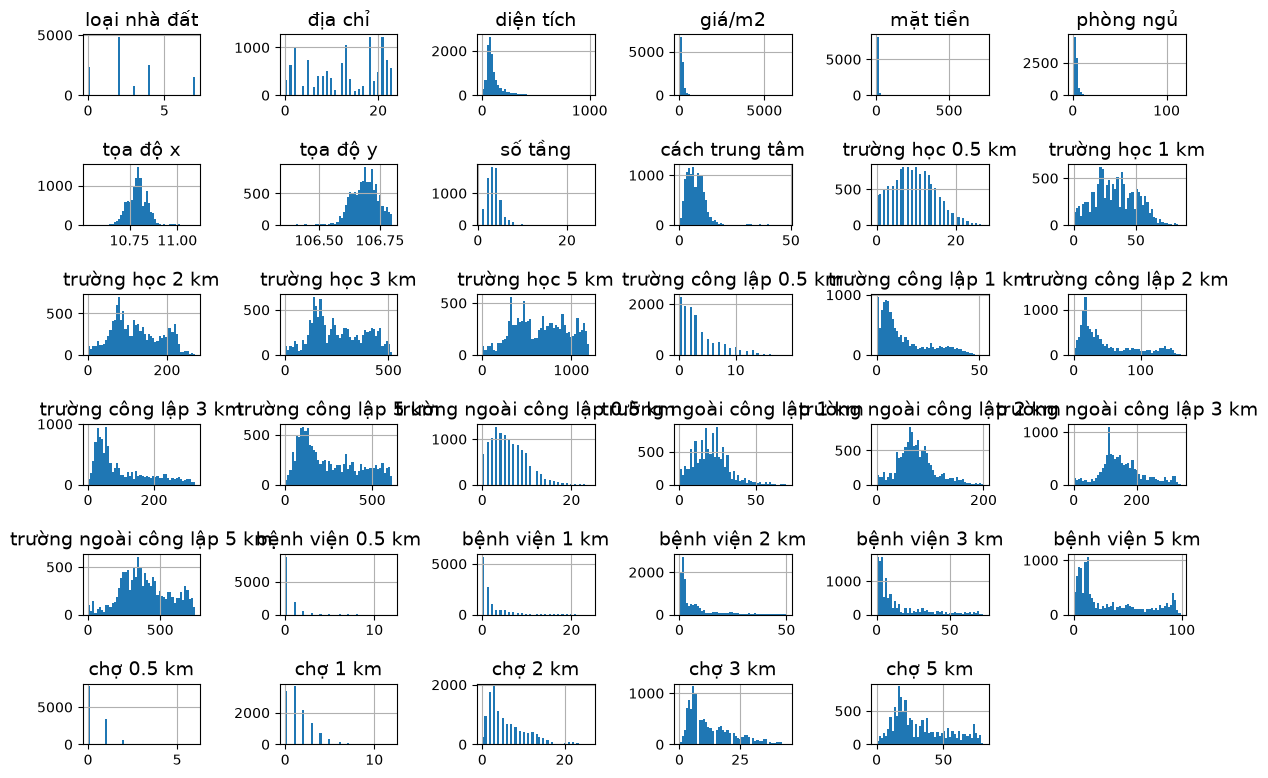

In [70]:
import matplotlib.pyplot as plt

# extra code – the next 5 lines define the default font sizes
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

df.hist(bins=50, figsize=(12, 8))
save_fig("attribute_histogram_plots")  # extra code
plt.show()

## Create data test

Giữ nguyên tỷ lệ phân bố của một biến quan trọng
trong cả train và test

In [71]:
np.random.seed(42)

In [72]:
df["distance_center_cat"] = pd.cut(df["cách trung tâm"],
                                    bins=[0., 5., 10., 15., np.inf],
                                    labels=[1, 2, 3, 4])

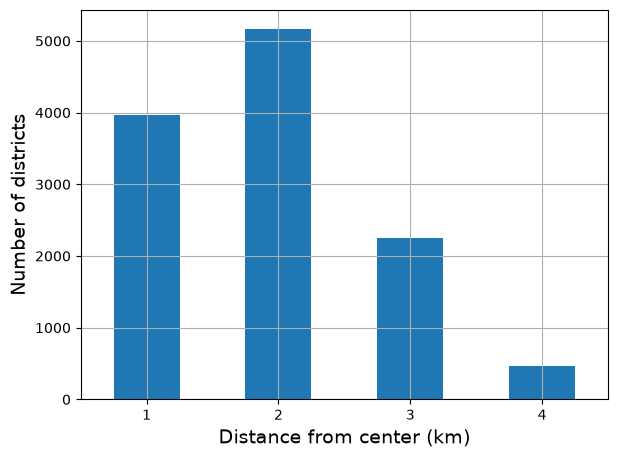

In [73]:
df["distance_center_cat"].value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("Distance from center (km)")
plt.ylabel("Number of districts")
save_fig("housing_distance_cat_bar_plot")  # extra code
plt.show()

In [74]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=42)
strat_splits = []
for train_index, test_index in splitter.split(df, df["distance_center_cat"]):
    strat_train_set_n = df.iloc[train_index]
    strat_test_set_n = df.iloc[test_index]
    strat_splits.append([strat_train_set_n, strat_test_set_n])

In [75]:
strat_train_set, strat_test_set = strat_splits[0]

In [76]:
df["distance_center_cat"].value_counts() / len(df)

distance_center_cat
2    0.436319
1    0.334683
3    0.189777
4    0.039221
Name: count, dtype: float64

In [77]:
strat_train_set["distance_center_cat"].value_counts() / len(strat_train_set)

distance_center_cat
2    0.436314
1    0.334669
3    0.189793
4    0.039224
Name: count, dtype: float64

In [78]:
strat_test_set["distance_center_cat"].value_counts() / len(strat_test_set)

distance_center_cat
2    0.436341
1    0.334739
3    0.189713
4    0.039207
Name: count, dtype: float64

In [79]:
for set_ in (strat_train_set, strat_test_set):
    set_.drop("distance_center_cat", axis=1, inplace=True)

C:\Users\huypro37\AppData\Local\Temp\ipykernel_21104\3306667349.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  set_.drop("distance_center_cat", axis=1, inplace=True)


In [80]:
train_set = strat_train_set
test_set = strat_test_set

In [81]:
print(f"train set shape: {train_set.shape}")
print(f"test set shape: {test_set.shape}")

train set shape: (9484, 35)
test set shape: (2372, 35)


# Discover and Visualize the Data to Gain Insights

In [82]:
housing = train_set.copy()

## Visualizing Geographical Data

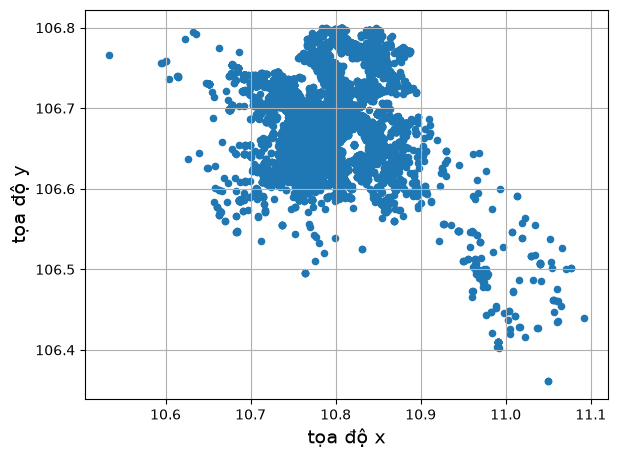

In [83]:
housing.plot(kind="scatter", x="tọa độ x", y="tọa độ y", grid=True)
save_fig("bad_visualization_plot")  # extra code
plt.show()

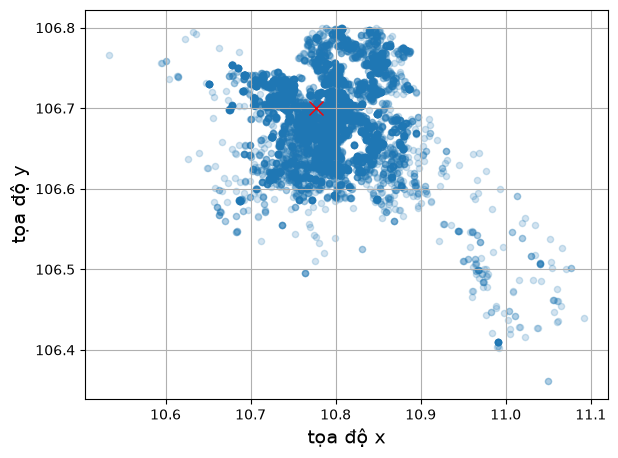

In [84]:
housing.plot(kind="scatter", x="tọa độ x", y="tọa độ y", grid=True, alpha=0.2)
# vẽ dấu x biểu thị trung tâm thành phố
plt.plot(lat, lon, "x", color="red", markersize=10, label="Trung tâm thành phố")
save_fig("better_visualization_plot")  # extra code
plt.show()

# Biểu đồ tương quan các feature

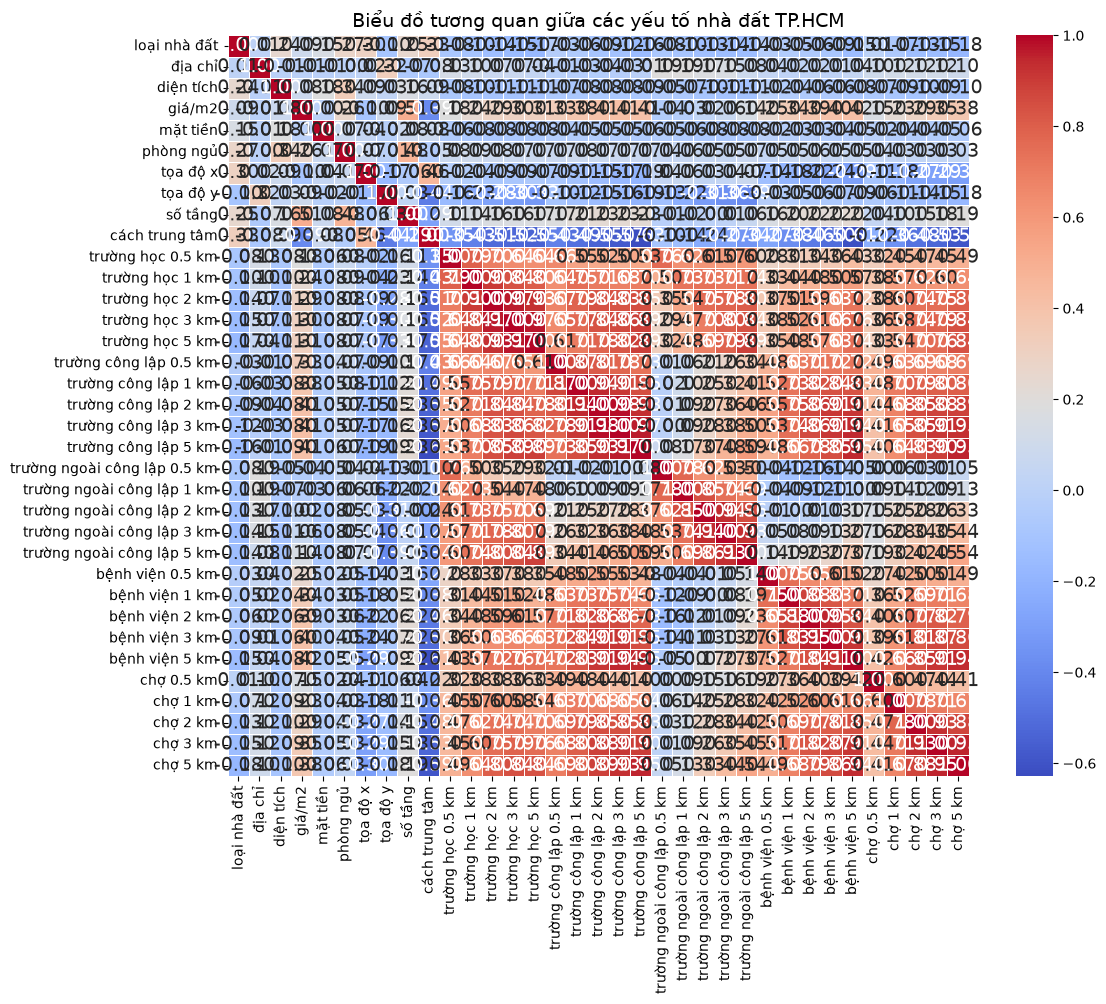

In [85]:
import seaborn as sns

corr_matrix = housing.corr(numeric_only=True)

# 2. Thiết lập kích thước biểu đồ
plt.figure(figsize=(12, 10))

# 3. Vẽ heatmap
sns.heatmap(corr_matrix, 
            annot=True,       # Hiển thị số liệu trên từng ô
            fmt=".2f",        # Làm tròn 2 chữ số thập phân
            cmap='coolwarm',  # Màu sắc (Đỏ: tương quan thuận, Xanh: tương quan nghịch)
            linewidths=0.5,   # Khoảng cách giữa các ô
            square=True)      # Giữ các ô là hình vuông

plt.title('Biểu đồ tương quan giữa các yếu tố nhà đất TP.HCM')
save_fig("correlation_heatmap")  # extra code
plt.show()

In [86]:
corr_matrix = housing.corr(numeric_only=True)

In [87]:
corr_matrix["giá/m2"].sort_values(ascending=False)

giá/m2                          1.000000
số tầng                         0.506557
bệnh viện 5 km                  0.420684
trường công lập 3 km            0.414822
trường công lập 5 km            0.407369
trường công lập 2 km            0.407027
bệnh viện 3 km                  0.403163
bệnh viện 2 km                  0.387846
trường công lập 1 km            0.379239
chợ 5 km                        0.375038
chợ 3 km                        0.345997
bệnh viện 1 km                  0.338476
trường công lập 0.5 km          0.330424
trường học 5 km                 0.309707
trường học 3 km                 0.304961
chợ 2 km                        0.293127
trường học 2 km                 0.290883
phòng ngủ                       0.257283
bệnh viện 0.5 km                0.252509
trường học 1 km                 0.238457
chợ 1 km                        0.225193
trường học 0.5 km               0.181369
chợ 0.5 km                      0.153640
trường ngoài công lập 5 km      0.143864
loại nhà đất    

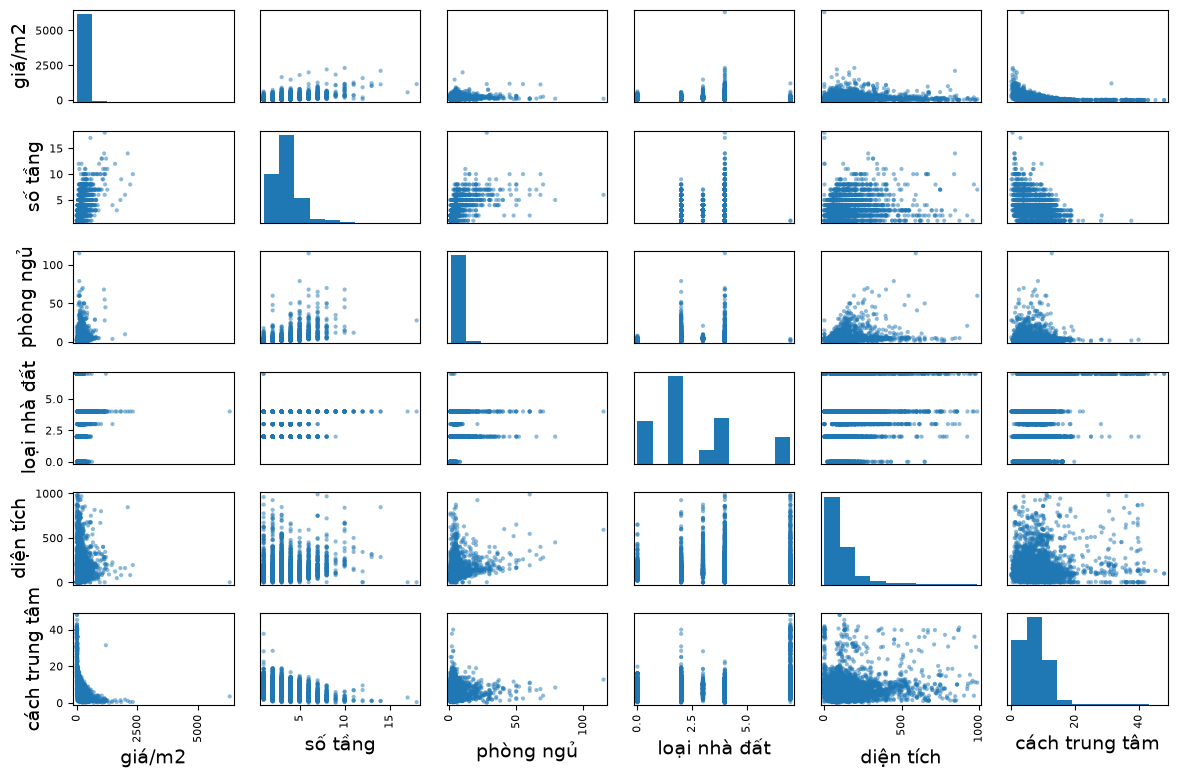

In [88]:
from pandas.plotting import scatter_matrix

attributes = ["giá/m2", "số tầng", "phòng ngủ", "loại nhà đất", "diện tích", "cách trung tâm"]

scatter_matrix(housing[attributes], figsize=(12, 8))
save_fig("scatter_matrix_plot")  # extra code
plt.show()  

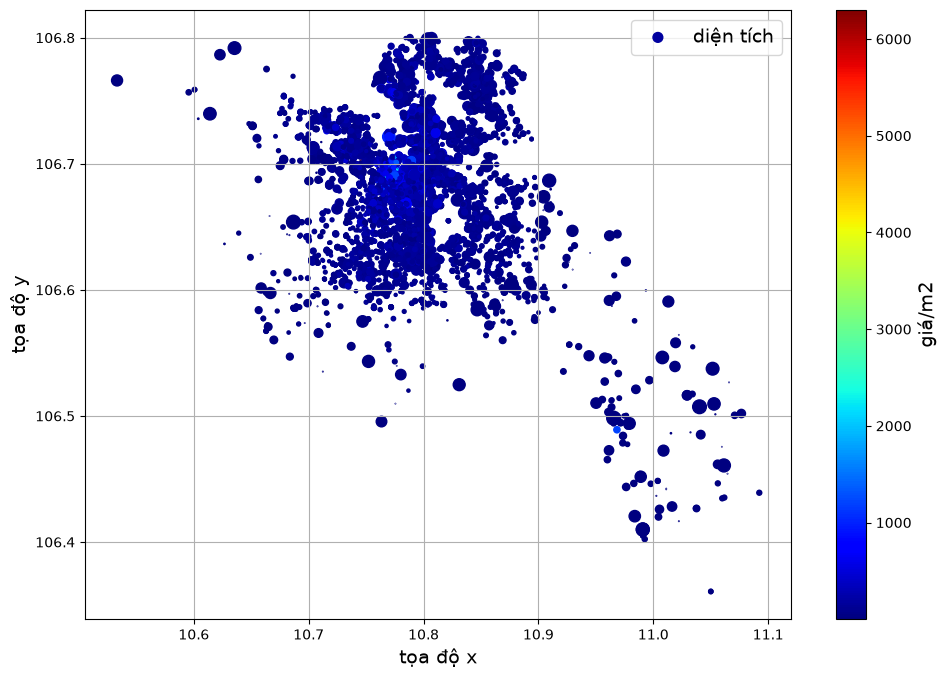

In [89]:
housing.plot(kind="scatter", x="tọa độ x", y="tọa độ y", grid=True,
             s=housing["diện tích"]/10 , label="diện tích",
             c="giá/m2", cmap="jet", colorbar=True,
             legend=True, sharex=False, figsize=(10, 7))
save_fig("housing_prices_scatterplot")  # extra code
plt.show()

## Data cleaning


In [90]:
housing.describe()

,loại nhà đất,địa chỉ,diện tích,giá/m2,mặt tiền,phòng ngủ,tọa độ x,tọa độ y,số tầng,cách trung tâm,...,bệnh viện 0.5 km,bệnh viện 1 km,bệnh viện 2 km,bệnh viện 3 km,bệnh viện 5 km,chợ 0.5 km,chợ 1 km,chợ 2 km,chợ 3 km,chợ 5 km
count,9484.000000,9484.000000,9484.000000,9484.000000,6771.000000,6814.000000,9484.000000,9484.000000,5507.000000,9484.000000,...,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000
mean,2.716892,12.587727,115.233465,148.280677,6.923735,4.295861,10.793684,106.687382,3.468313,7.462667,...,0.442957,1.667862,6.364192,13.431253,32.664804,0.405420,1.559574,6.007170,12.797237,32.729861
std,2.079990,7.361975,109.114667,146.762013,14.479814,4.949644,0.054246,0.056499,1.624326,4.942831,...,1.023201,2.862481,9.208816,17.151268,30.570431,0.623299,1.596003,4.743506,9.451782,20.256147
min,0.000000,0.000000,1.000000,1.020000,1.000000,1.000000,10.533189,106.360811,1.000000,0.023074,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,6.000000,60.000000,77.330000,4.000000,2.000000,10.761168,106.649926,2.000000,4.101567,...,0.000000,0.000000,1.000000,2.000000,8.000000,0.000000,0.000000,2.000000,6.000000,17.000000
50%,2.000000,13.000000,82.000000,114.860000,5.000000,3.000000,10.793044,106.690006,3.000000,6.739944,...,0.000000,1.000000,2.000000,6.000000,17.000000,0.000000,1.000000,4.000000,10.000000,26.000000
75%,4.000000,20.000000,125.000000,177.780000,7.000000,4.000000,10.827343,106.726112,4.000000,9.752661,...,1.000000,2.000000,8.000000,16.000000,54.000000,1.000000,2.000000,9.000000,18.000000,47.000000
max,7.000000,23.000000,990.000000,6300.000000,737.000000,115.000000,11.092275,106.799985,18.000000,47.974788,...,12.000000,24.000000,50.000000,73.000000,99.000000,6.000000,12.000000,26.000000,44.000000,80.000000


In [91]:
def set_median_none_in_column(df, column_names):
    for column_name in column_names:
        median_value = df[column_name].median()
        df[column_name] = df[column_name].fillna(median_value)

set_median_none_in_column(housing, ["số tầng", "phòng ngủ", "mặt tiền"])


In [92]:
housing.describe()

,loại nhà đất,địa chỉ,diện tích,giá/m2,mặt tiền,phòng ngủ,tọa độ x,tọa độ y,số tầng,cách trung tâm,...,bệnh viện 0.5 km,bệnh viện 1 km,bệnh viện 2 km,bệnh viện 3 km,bệnh viện 5 km,chợ 0.5 km,chợ 1 km,chợ 2 km,chợ 3 km,chợ 5 km
count,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,...,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000,9484.000000
mean,2.716892,12.587727,115.233465,148.280677,6.373430,3.931042,10.793684,106.687382,3.271932,7.462667,...,0.442957,1.667862,6.364192,13.431253,32.664804,0.405420,1.559574,6.007170,12.797237,32.729861
std,2.079990,7.361975,109.114667,146.762013,12.265302,4.235662,0.054246,0.056499,1.259099,4.942831,...,1.023201,2.862481,9.208816,17.151268,30.570431,0.623299,1.596003,4.743506,9.451782,20.256147
min,0.000000,0.000000,1.000000,1.020000,1.000000,1.000000,10.533189,106.360811,1.000000,0.023074,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,6.000000,60.000000,77.330000,4.000000,3.000000,10.761168,106.649926,3.000000,4.101567,...,0.000000,0.000000,1.000000,2.000000,8.000000,0.000000,0.000000,2.000000,6.000000,17.000000
50%,2.000000,13.000000,82.000000,114.860000,5.000000,3.000000,10.793044,106.690006,3.000000,6.739944,...,0.000000,1.000000,2.000000,6.000000,17.000000,0.000000,1.000000,4.000000,10.000000,26.000000
75%,4.000000,20.000000,125.000000,177.780000,5.540000,4.000000,10.827343,106.726112,4.000000,9.752661,...,1.000000,2.000000,8.000000,16.000000,54.000000,1.000000,2.000000,9.000000,18.000000,47.000000
max,7.000000,23.000000,990.000000,6300.000000,737.000000,115.000000,11.092275,106.799985,18.000000,47.974788,...,12.000000,24.000000,50.000000,73.000000,99.000000,6.000000,12.000000,26.000000,44.000000,80.000000


# Remove oulier

Cách 1: sử dụng iqr

In [93]:
def up_low_val_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return lower_bound, upper_bound

def remove_outliers_columns(df, columns):
    iqrs = []
    for column in columns:
        lower_bound, upper_bound = up_low_val_iqr(df, column)
        iqrs.append((lower_bound, upper_bound))
    for i, column in enumerate(columns):
        lower_bound, upper_bound = iqrs[i]
        df = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    return df



In [94]:
housing_1 = housing.copy()

columns_to_remove_outliers = ["diện tích", "giá/m2", "số tầng", "phòng ngủ", "mặt tiền"]
housing_1 = remove_outliers_columns(housing_1, columns_to_remove_outliers)

housing_1.describe()

,loại nhà đất,địa chỉ,diện tích,giá/m2,mặt tiền,phòng ngủ,tọa độ x,tọa độ y,số tầng,cách trung tâm,...,bệnh viện 0.5 km,bệnh viện 1 km,bệnh viện 2 km,bệnh viện 3 km,bệnh viện 5 km,chợ 0.5 km,chợ 1 km,chợ 2 km,chợ 3 km,chợ 5 km
count,6254.000000,6254.000000,6254.000000,6254.000000,6254.000000,6254.000000,6254.000000,6254.000000,6254.000000,6254.000000,...,6254.000000,6254.000000,6254.000000,6254.000000,6254.000000,6254.000000,6254.000000,6254.000000,6254.000000,6254.000000
mean,2.375120,12.738887,81.846041,118.280438,4.588483,3.115286,10.790907,106.687590,3.102494,7.594252,...,0.385034,1.440678,5.612408,12.110649,30.519348,0.391270,1.506236,5.784298,12.275504,31.743684
std,2.129352,7.461406,37.119977,62.083574,0.984063,0.871926,0.054022,0.055787,0.694418,4.480063,...,0.949790,2.561618,8.425727,15.882059,29.049892,0.616367,1.597078,4.633161,9.138733,19.573847
min,0.000000,0.000000,1.000000,1.300000,2.000000,2.000000,10.595106,106.360811,2.000000,0.243980,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,5.000000,57.000000,72.920000,4.000000,2.000000,10.751574,106.647680,3.000000,4.478454,...,0.000000,0.000000,1.000000,2.000000,7.000000,0.000000,0.000000,2.000000,6.000000,17.000000
50%,2.000000,13.000000,75.000000,105.800000,5.000000,3.000000,10.791877,106.689897,3.000000,7.093018,...,0.000000,0.000000,2.000000,6.000000,15.000000,0.000000,1.000000,4.000000,9.000000,25.000000
75%,3.000000,20.000000,100.000000,151.640000,5.000000,4.000000,10.827502,106.727195,3.000000,9.818993,...,0.000000,2.000000,7.000000,14.000000,50.000000,1.000000,2.000000,8.000000,17.000000,44.000000
max,7.000000,23.000000,222.000000,327.510000,7.750000,5.000000,11.092275,106.799964,5.000000,47.974788,...,12.000000,21.000000,50.000000,73.000000,98.000000,6.000000,12.000000,26.000000,43.000000,80.000000


In [95]:
housing_1.shape

(6254, 35)

Cách 2: Loại bỏ theo logic thực tế

In [96]:
housing_2 = housing.copy()
housing_2= housing_2[housing_2["phòng ngủ"] < 11]
housing_2 = housing_2[housing_2["mặt tiền"] <= 30]
housing_2 = housing_2[housing_2["giá/m2"] <= 500]
housing_2 = housing_2[housing_2["diện tích"] <= 500]
housing_2 = housing_2[(housing_2["diện tích"] >= 15)]



In [97]:
housing_2.describe()

,loại nhà đất,địa chỉ,diện tích,giá/m2,mặt tiền,phòng ngủ,tọa độ x,tọa độ y,số tầng,cách trung tâm,...,bệnh viện 0.5 km,bệnh viện 1 km,bệnh viện 2 km,bệnh viện 3 km,bệnh viện 5 km,chợ 0.5 km,chợ 1 km,chợ 2 km,chợ 3 km,chợ 5 km
count,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,...,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000
mean,2.585518,12.719367,103.018037,134.536474,5.410771,3.354775,10.792334,106.688560,3.167571,7.383203,...,0.422566,1.609308,6.173577,13.078877,32.104285,0.402587,1.552373,5.983716,12.715441,32.562652
std,2.060570,7.364908,73.173303,83.215590,2.919426,1.426660,0.052056,0.054970,1.048702,4.449564,...,0.997967,2.794768,9.008544,16.805950,30.033078,0.623571,1.597996,4.739028,9.390362,19.987888
min,0.000000,0.000000,15.000000,2.740000,1.000000,1.000000,10.595573,106.360811,1.000000,0.023074,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,6.000000,60.000000,77.780000,4.000000,3.000000,10.758335,106.649926,3.000000,4.225220,...,0.000000,0.000000,1.000000,2.000000,8.000000,0.000000,0.000000,2.000000,6.000000,17.000000
50%,2.000000,13.000000,80.000000,113.370000,5.000000,3.000000,10.792673,106.690399,3.000000,6.847699,...,0.000000,1.000000,2.000000,6.000000,16.000000,0.000000,1.000000,4.000000,10.000000,26.000000
75%,4.000000,20.000000,118.000000,171.430000,5.000000,4.000000,10.825791,106.727250,3.000000,9.725494,...,0.000000,2.000000,7.000000,15.000000,53.000000,1.000000,2.000000,8.000000,18.000000,47.000000
max,7.000000,23.000000,500.000000,500.000000,30.000000,10.000000,11.092275,106.799985,11.000000,47.974788,...,12.000000,22.000000,50.000000,73.000000,98.000000,6.000000,12.000000,26.000000,44.000000,80.000000


Nhìn vào mô tả dữ liệu từ 2 cách, ta thấy:
- Cách 1 tuy cho ra các dữ liệu sạch, và đẹp mắt nhưng lại trở nên quá nhỏ. Thực tế ở Tp.HCM có nhiều biệt thự, nhà riêng lớn vẫn rao bán.
- Cách 2, giữ lại được nhiều dữ liệu, tuy nhiên vẫn còn nhiều outlier.


Chọn cách 2 vì:
- giữ nhiều dữ liệu hơn
- không loại dữ liệu hợp lý
- model học được nhiều pattern hơn

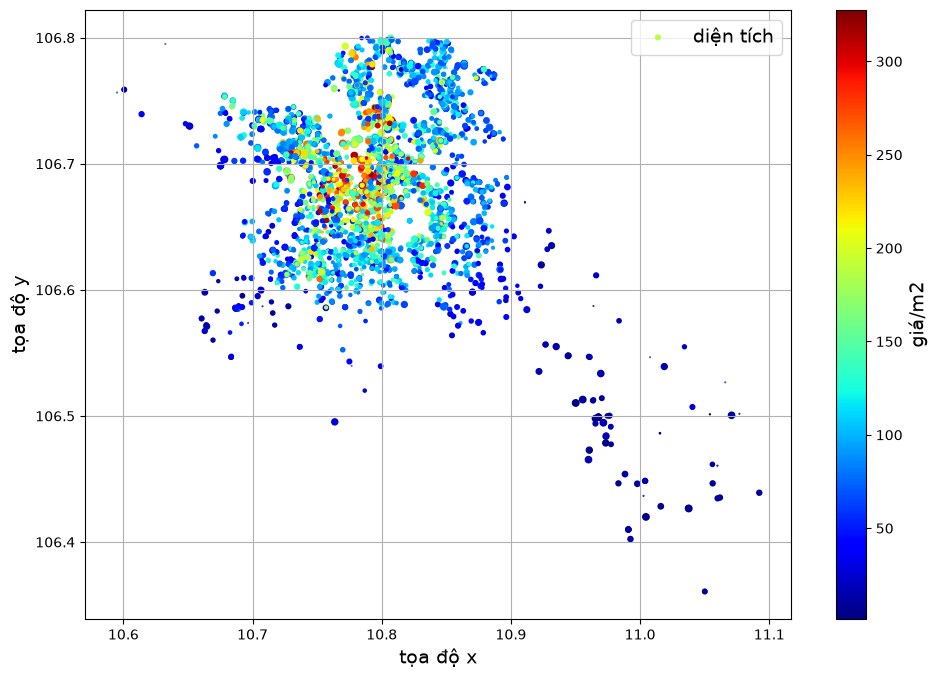

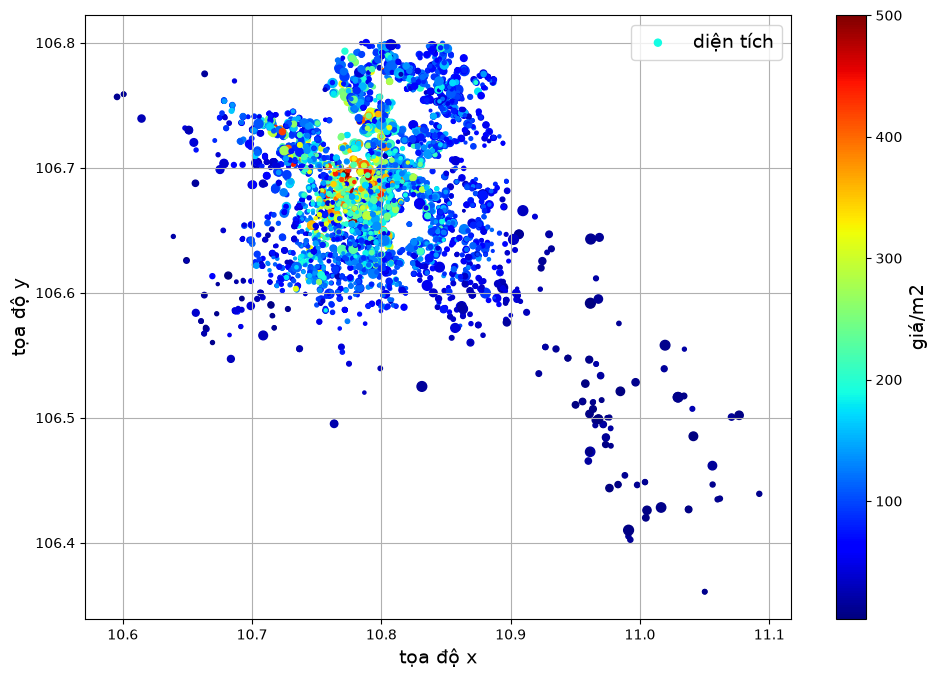

In [98]:
housing_1.plot(kind="scatter", x="tọa độ x", y="tọa độ y", grid=True,
             s=housing_1["diện tích"]/10 , label="diện tích",
             c="giá/m2", cmap="jet", colorbar=True,
             legend=True, sharex=False, figsize=(10, 7))
save_fig("housing_1_prices_scatterplot")  # extra code

housing_2.plot(kind="scatter", x="tọa độ x", y="tọa độ y", grid=True,
             s=housing_2["diện tích"]/10 , label="diện tích",
             c="giá/m2", cmap="jet", colorbar=True,
             legend=True, sharex=False, figsize=(10, 7))
save_fig("housing_2_prices_scatterplot")  # extra code

plt.show()




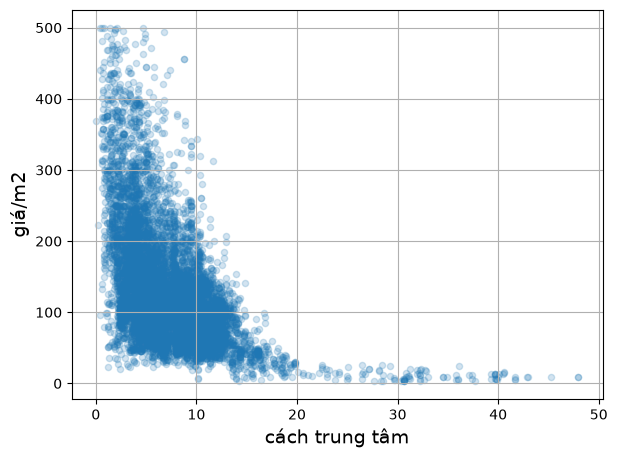

In [99]:
housing_2.plot(kind="scatter", x="cách trung tâm", y="giá/m2", grid=True, alpha=0.2)
save_fig("distance_center_vs_price_plot")  # extra code
plt.show()

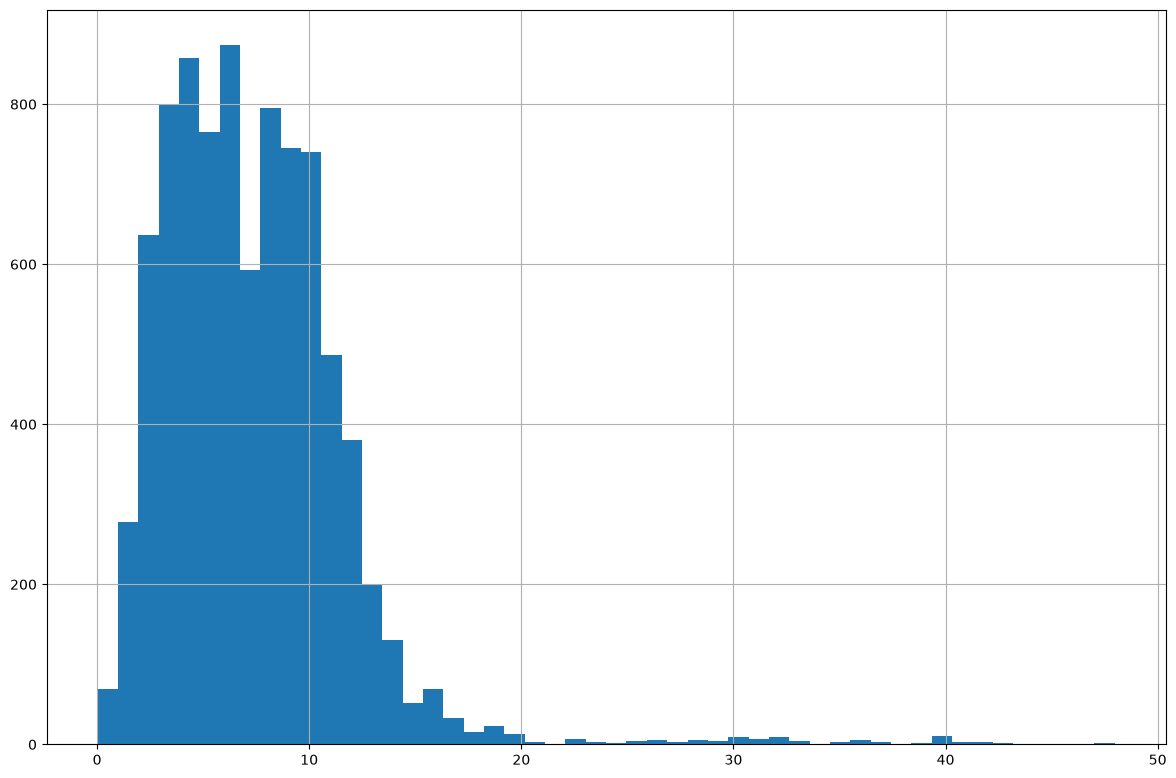

In [100]:
housing_2["cách trung tâm"].hist(bins=50, figsize=(12, 8))
save_fig("distance_center_histogram")  # extra code

data của khoảng cách tới trung tâm hơi lệch phải, ta sử dụng hàm log để tránh bị ảnh hưởng bởi outlier

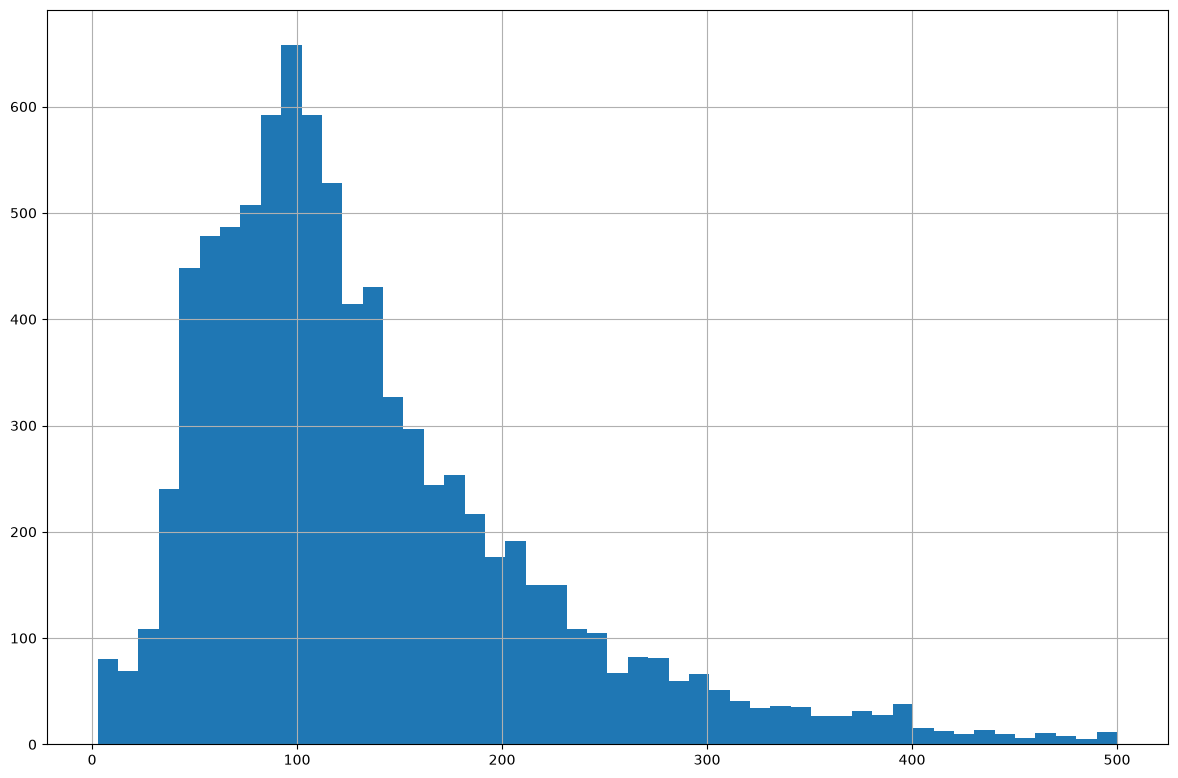

In [101]:
housing_2["giá/m2"].hist(bins=50, figsize=(12, 8))
save_fig("price_per_sqm_histogram")  # extra code

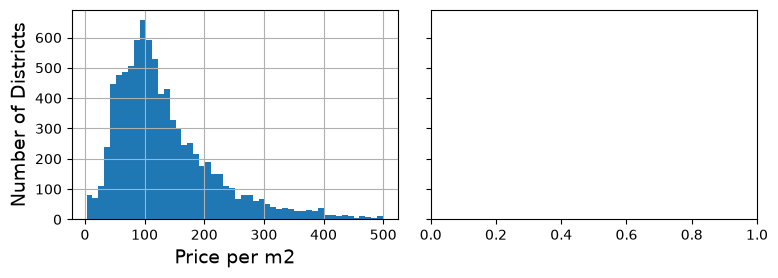

In [102]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
housing_2["giá/m2"].hist(ax=axs[0], bins=50)

axs[0].set_xlabel("Price per m2")
# axs[1].set_xlabel("Log of Price per m2")
axs[0].set_ylabel("Number of Districts")
save_fig("price_per_sqm_plot")  # extra code
plt.show()

Hàm log với distance to center không có quá nhiều thay đổi, ta quyết định sử dụng data gốc

## Giá trung bình theo quận

In [103]:
housing_test = housing_2.copy()
housing_test["district_mean_area"] = housing_test.groupby("địa chỉ")["giá/m2"].transform("mean")
mean_area = housing_test[["địa chỉ", "district_mean_area"]].copy()
mean_area.drop_duplicates(inplace=True)
mean_area.sort_values(by="district_mean_area", ascending=False, inplace=True)
# Kết hợp với tên quận để dễ nhìn
# (pandas 3 không cho gán chuỗi vào cột int nên dùng map thay vì .loc)
mean_area["địa chỉ"] = mean_area["địa chỉ"].map({v: k for k, v in ADDRESS_.items()})

print(mean_area)


          địa chỉ  district_mean_area
33254      quận 1          285.197273
42492      quận 3          251.618148
32344     quận 10          222.449283
4399    phú nhuận          193.130937
32316      quận 5          186.187083
29980    tân bình          167.193339
30028  bình thạnh          157.902082
37421     quận 11          156.123182
2736       quận 2          154.667557
39645      quận 4          136.074333
39054      gò vấp          129.958817
2643       quận 7          127.850043
30090      quận 6          120.984792
28323     tân phú          115.476461
42636     thủ đức          105.077220
17807      quận 9          104.048579
24607      quận 8          101.915941
1182     bình tân           95.672495
29189     quận 12           82.746994
26384      nhà bè           79.041223
26434  bình chánh           59.533287
32739     hóc môn           43.938376
5299      cần giờ           15.380000
700        củ chi           11.672308


C:\Users\huypro37\AppData\Local\Temp\ipykernel_21104\2481413436.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  mean_area.drop_duplicates(inplace=True)
C:\Users\huypro37\AppData\Local\Temp\ipykernel_21104\2481413436.py:5: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  mean_area.sort_values(by="district_mean_area", ascending=False, inplace=True)


In [104]:
REAL_ESTATE_VAL = {
     0: 'căn hộ chung cư',
    1: 'chung cư mini, căn hộ dịch vụ', # X
    2: 'nhà riêng', 
    3: 'nhà biệt thự, liền kề',
    4: 'nhà mặt phố',
    5: 'shophouse, nhà phố thương mại', # X
    6: 'đất nền dự án', # X
    7: 'bán đất',
    8: 'condotel', # X
    9: 'kho nhà xưởng' # X
}


ADDRESS_VAL = {
    0: 'bình chánh',
    1: 'bình tân',
    2: 'bình thạnh',
    3: 'cần giờ',
    4: 'củ chi',
    5: 'gò vấp',
    6: 'hóc môn',
    7: 'nhà bè',
    8: 'phú nhuận',
    9: 'quận 1',
    10: 'quận 10',
    11: 'quận 11',
    12: 'quận 12',#
    13: 'quận 2',#
    14: 'quận 3',
    15: 'quận 4',
    16: 'quận 5',
    17: 'quận 6',
    18: 'quận 7',
    19: 'quận 8',
    20: 'quận 9',
    21: 'thủ đức',
    22: 'tân bình',
    23: 'tân phú'
}

In [105]:
# tạo mảng 2 chiều về giá trị trung bình của từng loại nhà đất theo từng quận
housing_test["type_district_mean_area"] = housing_test.groupby(["loại nhà đất", "địa chỉ"])["giá/m2"].transform("mean")
type_district_mean_area = housing_test[["loại nhà đất", "địa chỉ", "type_district_mean_area"]]
type_district_mean_area.drop_duplicates(inplace=True)   



C:\Users\huypro37\AppData\Local\Temp\ipykernel_21104\2789636472.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  type_district_mean_area.drop_duplicates(inplace=True)


In [106]:
type_district_mean_area["loại nhà đất"] = type_district_mean_area["loại nhà đất"].map(REAL_ESTATE_VAL)
type_district_mean_area["địa chỉ"] = type_district_mean_area["địa chỉ"].map(ADDRESS_VAL)
print(type_district_mean_area)

                loại nhà đất     địa chỉ  type_district_mean_area
30028              nhà riêng  bình thạnh               153.113718
17807        căn hộ chung cư      quận 9                53.510943
1182               nhà riêng    bình tân                97.845510
29980              nhà riêng    tân bình               146.089733
42636              nhà riêng     thủ đức               102.743426
...                      ...         ...                      ...
1251   nhà biệt thự, liền kề     quận 10               288.110000
1902                 bán đất   phú nhuận               149.670000
5299                 bán đất     cần giờ                15.380000
28048  nhà biệt thự, liền kề      quận 5               216.810000
2012   nhà biệt thự, liền kề      quận 3               185.000000

[108 rows x 3 columns]


In [107]:
pivot_table = type_district_mean_area.pivot_table(
    values="type_district_mean_area",
    index="địa chỉ",
    columns="loại nhà đất",
    aggfunc="mean"
)

pivot_table.round(2)

loại nhà đất,bán đất,căn hộ chung cư,"nhà biệt thự, liền kề",nhà mặt phố,nhà riêng
địa chỉ,,,,,
bình chánh,30.87,46.95,126.98,107.15,19.57
bình thạnh,125.38,104.35,172.70,245.75,153.11
bình tân,72.18,54.15,130.88,135.64,97.85
cần giờ,15.38,NaN,NaN,NaN,NaN
củ chi,11.30,NaN,NaN,11.00,16.82
gò vấp,97.97,52.72,208.73,173.18,125.58
hóc môn,34.00,NaN,59.52,57.33,47.48
nhà bè,47.71,56.51,116.58,104.69,89.36
phú nhuận,149.67,88.59,318.75,294.20,184.87


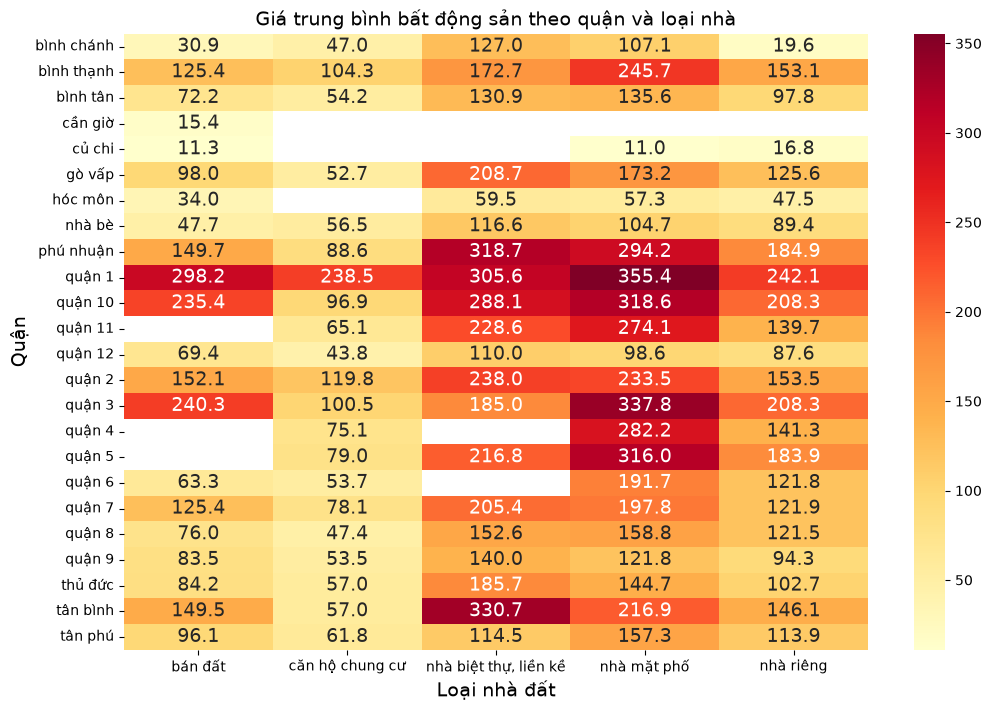

In [108]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))

sns.heatmap(
    pivot_table,
    annot=True,
    cmap="YlOrRd",
    fmt=".1f"
)

plt.title("Giá trung bình bất động sản theo quận và loại nhà")
plt.xlabel("Loại nhà đất")
plt.ylabel("Quận")

plt.show()

In [109]:
# Hiển thị giá trị trung bình của từng loại nhà đất theo từng quận, hiện theo dạng bảng dễ nhìn
# địa chỉ là cột dọc, loại nhà đất là cột ngang
# Nếu cột nào không chứa dữ liệu thì sẽ hiển thị NaN
from tabulate import tabulate
type_district_mean_area["loại nhà đất"] = type_district_mean_area["loại nhà đất"].map(REAL_ESTATE_VAL)
type_district_mean_area["địa chỉ"] = type_district_mean_area["địa chỉ"].map(ADDRESS_VAL)
print(tabulate(type_district_mean_area, headers="keys", tablefmt="grid"))
# lưu bảng vào file csv
type_district_mean_area.to_csv("type_district_mean_area.csv", index=False)


+-------+----------------+-----------+---------------------------+
|       |   loại nhà đất |   địa chỉ |   type_district_mean_area |
+=======+================+===========+===========================+
| 30028 |            nan |       nan |                  153.114  |
+-------+----------------+-----------+---------------------------+
| 17807 |            nan |       nan |                   53.5109 |
+-------+----------------+-----------+---------------------------+
|  1182 |            nan |       nan |                   97.8455 |
+-------+----------------+-----------+---------------------------+
| 29980 |            nan |       nan |                  146.09   |
+-------+----------------+-----------+---------------------------+
| 42636 |            nan |       nan |                  102.743  |
+-------+----------------+-----------+---------------------------+
| 24607 |            nan |       nan |                   47.4324 |
+-------+----------------+-----------+------------------------

# Nhận xét về giá/m2

Giá có vẻ đang có oulier khá lớn nên ta sẽ sử dụng hàm log để giảm sử ảnh hưởng của giá

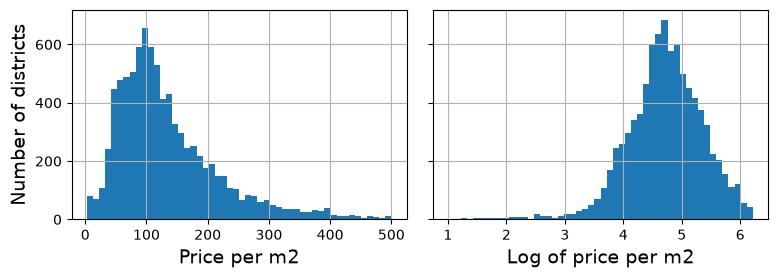

In [110]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
housing_2["giá/m2"].hist(ax=axs[0], bins=50)
housing_2["giá/m2"].apply(np.log).hist(ax=axs[1], bins=50)
axs[0].set_xlabel("Price per m2")
axs[1].set_xlabel("Log of price per m2")
axs[0].set_ylabel("Number of districts")
save_fig("long_tail_plot")
plt.show()

## Nhận xét về diện tích

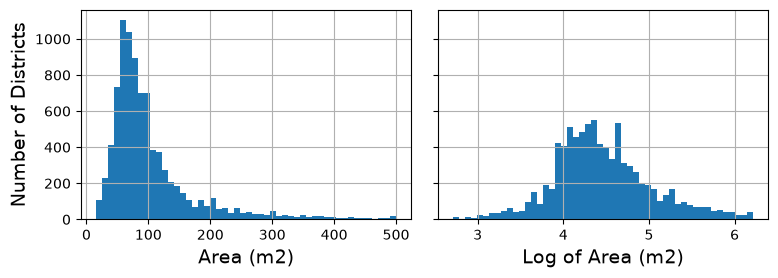

In [111]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
housing_2["diện tích"].hist(ax=axs[0], bins=50)
housing_2["diện tích"].apply(np.log).hist(ax=axs[1], bins=50)
axs[0].set_xlabel("Area (m2)")
axs[1].set_xlabel("Log of Area (m2)")
axs[0].set_ylabel("Number of Districts")
save_fig("long_area_plot")
plt.show()

In [112]:
housing_2.describe()

,loại nhà đất,địa chỉ,diện tích,giá/m2,mặt tiền,phòng ngủ,tọa độ x,tọa độ y,số tầng,cách trung tâm,...,bệnh viện 0.5 km,bệnh viện 1 km,bệnh viện 2 km,bệnh viện 3 km,bệnh viện 5 km,chợ 0.5 km,chợ 1 km,chợ 2 km,chợ 3 km,chợ 5 km
count,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,...,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000,8659.000000
mean,2.585518,12.719367,103.018037,134.536474,5.410771,3.354775,10.792334,106.688560,3.167571,7.383203,...,0.422566,1.609308,6.173577,13.078877,32.104285,0.402587,1.552373,5.983716,12.715441,32.562652
std,2.060570,7.364908,73.173303,83.215590,2.919426,1.426660,0.052056,0.054970,1.048702,4.449564,...,0.997967,2.794768,9.008544,16.805950,30.033078,0.623571,1.597996,4.739028,9.390362,19.987888
min,0.000000,0.000000,15.000000,2.740000,1.000000,1.000000,10.595573,106.360811,1.000000,0.023074,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,6.000000,60.000000,77.780000,4.000000,3.000000,10.758335,106.649926,3.000000,4.225220,...,0.000000,0.000000,1.000000,2.000000,8.000000,0.000000,0.000000,2.000000,6.000000,17.000000
50%,2.000000,13.000000,80.000000,113.370000,5.000000,3.000000,10.792673,106.690399,3.000000,6.847699,...,0.000000,1.000000,2.000000,6.000000,16.000000,0.000000,1.000000,4.000000,10.000000,26.000000
75%,4.000000,20.000000,118.000000,171.430000,5.000000,4.000000,10.825791,106.727250,3.000000,9.725494,...,0.000000,2.000000,7.000000,15.000000,53.000000,1.000000,2.000000,8.000000,18.000000,47.000000
max,7.000000,23.000000,500.000000,500.000000,30.000000,10.000000,11.092275,106.799985,11.000000,47.974788,...,12.000000,22.000000,50.000000,73.000000,98.000000,6.000000,12.000000,26.000000,44.000000,80.000000


## Train model

6️⃣ Một cải tiến rất đáng làm

Dataset của bạn có tọa độ.
Có thể thêm feature:

housing_2["area_density"] = housing_2["diện tích"] / housing_2["phòng ngủ"]

Hoặc:

housing_2["frontage_ratio"] = housing_2["mặt tiền"] / housing_2["diện tích"]

In [113]:
# Mô hình cũ không dùng đặc trưng POI (xem mục thí nghiệm ở cuối notebook)
X_train = housing_2.drop(columns=["giá/m2"] + POI_COLS)
# X_train["diện tích"] = X_train["diện tích"].apply(np.log)
y_train = np.log(housing_2["giá/m2"])


set_median_none_in_column(test_set, ["số tầng", "phòng ngủ", "mặt tiền"])
X_test = test_set.drop(columns=["giá/m2"] + POI_COLS)
# X_test["diện tích"] = X_test["diện tích"].apply(np.log)
y_test = np.log(test_set["giá/m2"])

In [114]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
import joblib as jb

pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

pipeline.fit(X_train, y_train)

model = pipeline.named_steps['model']

jb.dump(pipeline, "RandomForestRegressor.pkl")

['RandomForestRegressor.pkl']

In [115]:
X_train.columns

Index(['loại nhà đất', 'địa chỉ', 'diện tích', 'mặt tiền', 'phòng ngủ',
       'tọa độ x', 'tọa độ y', 'số tầng', 'cách trung tâm'],
      dtype='str')

In [116]:
X_test.describe()

,loại nhà đất,địa chỉ,diện tích,mặt tiền,phòng ngủ,tọa độ x,tọa độ y,số tầng,cách trung tâm
count,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000
mean,2.702361,12.445194,115.018769,5.899237,3.889123,10.792722,106.686692,3.273187,7.429181
std,2.047709,7.269584,111.328560,5.258890,4.121102,0.053846,0.056129,1.275764,4.870698
min,0.000000,0.000000,1.000000,1.000000,1.000000,10.632780,106.403759,1.000000,0.084247
25%,2.000000,6.000000,60.000000,4.000000,3.000000,10.760025,106.648943,3.000000,4.035230
50%,2.000000,13.000000,80.900000,4.900000,3.000000,10.791666,106.689097,3.000000,6.718773
75%,4.000000,19.000000,123.325000,5.300000,4.000000,10.826457,106.725446,4.000000,9.772103
max,7.000000,23.000000,996.000000,100.000000,87.000000,11.086623,106.799667,25.000000,42.906853


In [117]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

model = jb.load("RandomForestRegressor.pkl")
pred = model.predict(X_test)

def evaluate_model(model, X_test, y_test):
    pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    return rmse, mae, r2

rmse, mae, r2 = evaluate_model(model, X_test, y_test)

print(f"MAE: {mae:.2f}")
print(f"R2: {r2:.2f}")
print("RMSE: " + str(rmse))

MAE: 0.22
R2: 0.80
RMSE: 0.3378247047507193


In [118]:
price_pred = np.exp(pred)

In [119]:
price_pred[:10]

array([119.84125506, 157.21283491, 180.89481346, 213.65872663,
       222.99628217, 138.19171074,  12.27366689, 127.60277686,
        62.48294408, 360.99072019])

# Kiểm tra feature quan trọng

In [120]:
import pandas as pd

importance = pd.Series(
    model['model'].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance)

cách trung tâm    0.514178
loại nhà đất      0.169340
tọa độ x          0.078847
tọa độ y          0.064765
số tầng           0.063027
diện tích         0.060218
địa chỉ           0.023315
mặt tiền          0.015567
phòng ngủ         0.010742
dtype: float64


Top 3 features:
- distance_center_km
- loại nhà đất
- tọa độ

Ba đặc trưng quan trọng nhất chiếm hơn 75% tổng độ quan trọng của mô hình, cho thấy vị trí và loại hình bất động sản là các yếu tố quyết định chính đến giá.

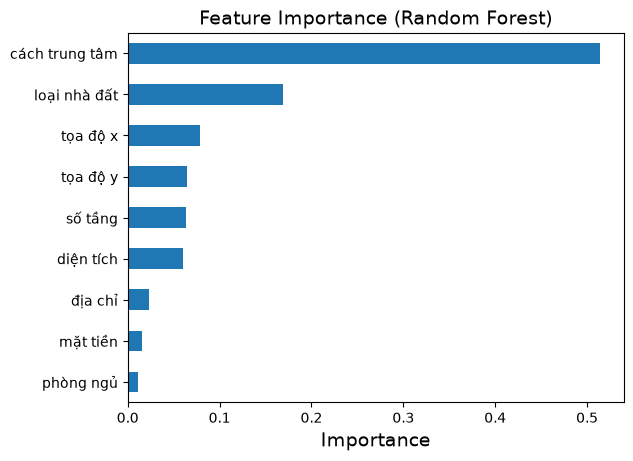

<Figure size 640x480 with 0 Axes>

In [121]:
importance.sort_values().plot(kind="barh")
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance")
plt.show()
plt.savefig("feature_importance_plot.png", dpi=300, bbox_inches='tight')

## Load model to test

In [122]:
pipeline = jb.load("RandomForestRegressor.pkl")

median = pipeline.named_steps['imputer'].statistics_
model = pipeline.named_steps['model']

median_series = pd.Series(median, index=X_train.columns)

In [123]:
print(X_train.columns)

Index(['loại nhà đất', 'địa chỉ', 'diện tích', 'mặt tiền', 'phòng ngủ',
       'tọa độ x', 'tọa độ y', 'số tầng', 'cách trung tâm'],
      dtype='str')


In [124]:
# {"loại nhà đất": 0, "địa chỉ": 2, "giá": 9500.0, "diện tích": 80.0, "giá/m2": 118.75, "mặt tiền": null, "phòng ngủ": 2, "pháp lý": 1, "tọa độ": null, 
# "tọa độ x": 10795419054.8442, "tọa độ y": 106719977458.315, "số tầng": null}


test_data = pd.DataFrame({
    'loại nhà đất': [0],
    'địa chỉ': [2],
    'diện tích': [80],
    'mặt tiền': [None],
    'phòng ngủ': [2],
    # 'pháp lý': [1],
    'tọa độ x': [10795419054.8442 / 1000000000],
    'tọa độ y': [106719977458.315 / 1000000000],
    'số tầng': [None]
})

test_data["cách trung tâm"] = haversine(
    test_data["tọa độ x"],
    test_data["tọa độ y"],
    lat,
    lon
)
# fill missing values with median
test_data.fillna(median_series, inplace=True)

# print(test_data)
# 10.7795105160091,106.624395422216
predicted_price_per_m2 = np.exp(model.predict(test_data))
print(f"Giá dự đoán cho nhà đất: {predicted_price_per_m2[0]:.5f} triệu/m2")
print(f"Giá dự đoán cho nhà đất: {predicted_price_per_m2[0] * np.exp(test_data['diện tích'][0]):.5f} triệu")

Giá dự đoán cho nhà đất: 119.22424 triệu/m2
Giá dự đoán cho nhà đất: 6605764726531800173573884082412060672.00000 triệu


d:\my_project\DoAn2\Multi-Agent-RAG-and-Prediction-Housing-Price\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(


## Train thêm model 
LinearRegression, DecisionTree, KNearestNeightbor, XGBoost

In [125]:
# Chạy thêm các model: LinearRegression, DecisionTree, KNearestNeightbor, XGBoost

import joblib
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.cluster import KMeans
from xgboost import XGBRegressor

# Thêm lưu model trong m
pipeline_list = [
    Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LinearRegression())
    ]),
    Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),
    Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", KNeighborsRegressor())
    ]),
    Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBRegressor(random_state=42))
    ])
]
models = {}


for pipe in pipeline_list:
    # train
    pipe.fit(X_train, y_train)

    # lấy tên model
    model_name = pipe.named_steps["model"].__class__.__name__

    # lưu model
    joblib.dump(pipe, f"{model_name}.pkl")
    models[model_name] = pipe
    print(f"Saved {model_name}.pkl")


Saved LinearRegression.pkl
Saved DecisionTreeRegressor.pkl
Saved KNeighborsRegressor.pkl
Saved XGBRegressor.pkl


In [126]:
def evaluate_model(model, X_test, y_test):
    pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    return rmse, mae, r2

for model_name, model in models.items():
    rmse, mae, r2 = evaluate_model(model.named_steps["model"], X_test, y_test)
    print(f"{model_name} - RMSE: {rmse:.2f}, MAE: {mae:.2f}, R2: {r2:.2f}")


pipeline = jb.load("RandomForestRegressor.pkl")
rmse, mae, r2 = evaluate_model(pipeline.named_steps["model"], X_test, y_test)

print(f"RandomForestRegressor - RMSE: {rmse:.2f}, MAE: {mae:.2f}, R2: {r2:.2f}")


LinearRegression - RMSE: 0.55, MAE: 0.39, R2: 0.48
DecisionTreeRegressor - RMSE: 0.44, MAE: 0.28, R2: 0.67
KNeighborsRegressor - RMSE: 0.50, MAE: 0.32, R2: 0.57
XGBRegressor - RMSE: 0.35, MAE: 0.23, R2: 0.78


d:\my_project\DoAn2\Multi-Agent-RAG-and-Prediction-Housing-Price\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(
d:\my_project\DoAn2\Multi-Agent-RAG-and-Prediction-Housing-Price\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
d:\my_project\DoAn2\Multi-Agent-RAG-and-Prediction-Housing-Price\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but KNeighborsRegressor was fitted without feature names
  warnings.warn(


RandomForestRegressor - RMSE: 0.34, MAE: 0.22, R2: 0.80


d:\my_project\DoAn2\Multi-Agent-RAG-and-Prediction-Housing-Price\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(


| Mô hình                 | RMSE | MAE  | R²   |
| ----------------------- | ---- | ---- | ---- |
| Linear Regression       | 0.59 | 0.41 | 0.38 |
| Decision Tree Regressor | 0.40 | 0.27 | 0.71 |
| KNeighbors Regressor    | 0.52 | 0.35 | 0.51 |
| XGBoost Regressor       | 0.35 | 0.24 | 0.78 |
| Random Forest Regressor | 0.33 | 0.22 | 0.81 |


## Phân tích kết quả
- Kết quả thực nghiệm cho thấy mô hình Linear Regression cho hiệu quả thấp nhất với hệ số R² chỉ đạt 0.22. Điều này cho thấy mối quan hệ giữa các thuộc tính bất động sản và giá bán không mang tính tuyến tính đơn giản.

- Mô hình Decision Tree Regressor cải thiện đáng kể kết quả so với Linear Regression với R² đạt 0.69. Điều này cho thấy các mô hình dựa trên cây có khả năng nắm bắt các mối quan hệ phi tuyến trong dữ liệu tốt hơn.

- Mô hình K-Nearest Neighbors cho kết quả trung bình với R² đạt 0.49. Phương pháp này phụ thuộc nhiều vào khoảng cách giữa các điểm dữ liệu nên dễ bị ảnh hưởng bởi nhiễu và sự phân bố không đồng đều của dữ liệu.

- Hai mô hình cho kết quả tốt nhất là Random Forest Regressor và XGBoost Regressor, với R² đạt khoảng 0.78 và sai số RMSE thấp nhất. Điều này cho thấy các mô hình ensemble dựa trên nhiều cây quyết định có khả năng học được các mối quan hệ phức tạp trong dữ liệu bất động sản.

Dựa trên kết quả thực nghiệm, mô hình Random Forest Regressor được lựa chọn làm mô hình chính của hệ thống.

Lý do lựa chọn Random Forest bao gồm:

+ Khả năng dự đoán chính xác với sai số thấp

+ Ít bị overfitting hơn so với Decision Tree đơn lẻ

+ Hoạt động ổn định với dữ liệu có nhiều đặc trưng khác nhau

+ Cho phép phân tích mức độ quan trọng của các đặc trưng (feature importance)

Mô hình sau khi huấn luyện được lưu lại dưới dạng file .pkl để phục vụ cho việc tích hợp vào hệ thống web trong bước triển khai tiếp theo.

## FINE-TURNING

In [127]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    "n_estimators": [100,200,300],
    "max_depth": [10,20,30,None],
    "min_samples_split": [2,5,10],
    "min_samples_leaf": [1,2,4]
}

rf = RandomForestRegressor()

search = RandomizedSearchCV(
    rf,
    param_grid,
    n_iter=20,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_

In [128]:
rmse, mae, r2 = evaluate_model(best_model, X_test, y_test)
print(f"Best RandomForestRegressor - RMSE: {rmse:.2f}, MAE: {mae:.2f}, R2: {r2:.2f}")

Best RandomForestRegressor - RMSE: 0.34, MAE: 0.22, R2: 0.80


In [129]:
search.best_params_

{'n_estimators': 300,
 'min_samples_split': 2,
 'min_samples_leaf': 1,
 'max_depth': None}

In [130]:
jb.dump(best_model, "Best_RandomForestRegressor.pkl")

['Best_RandomForestRegressor.pkl']

In [131]:
import joblib as jb
import numpy as np
import pandas as pd

pipeline = jb.load("RandomForestRegressor.pkl")
median = pipeline.named_steps['imputer'].statistics_
model = pipeline.named_steps['model']

X_train_columns = ['loại nhà đất', 'địa chỉ', 'diện tích', 'mặt tiền', 'phòng ngủ',
       'tọa độ x', 'tọa độ y', 'số tầng', 'distance_center_km']
median_series = pd.Series(median, index=X_train_columns)

lat = 10.7769
lon = 106.7009

def haversine(lat1, lon1, lat2, lon2):
    R = 6371

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat/2)**2 + \
        np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2

    c = 2*np.arcsin(np.sqrt(a))

    return R*c

# {"loại nhà đất": 0, "địa chỉ": 2, "giá": 9500.0, "diện tích": 80.0, "giá/m2": 118.75, "mặt tiền": null, "phòng ngủ": 2, "pháp lý": 1, "tọa độ": null, 
# "tọa độ x": 10795419054.8442, "tọa độ y": 106719977458.315, "số tầng": null}



test_data = pd.DataFrame({
    'loại nhà đất': [0],
    'địa chỉ': [2],
    'diện tích': [80],
    'mặt tiền': [None],
    'phòng ngủ': [2],
    # 'pháp lý': [1],
    'tọa độ x': [10795419054.8442 / 1000000000],
    'tọa độ y': [106719977458.315 / 1000000000],
    'số tầng': [None]
})

test_data["distance_center_km"] = haversine(
    test_data["tọa độ x"],
    test_data["tọa độ y"],
    lat,
    lon
)
# fill missing values with median
test_data.fillna(median_series, inplace=True)

# print(test_data)
# 10.7795105160091,106.624395422216
predicted_price_per_m2 = np.exp(model.predict(test_data))
print(f"Giá dự đoán cho nhà đất: {predicted_price_per_m2[0]:.5f} triệu/m2")
print(f"Giá dự đoán cho nhà đất: {predicted_price_per_m2[0] * test_data['diện tích'][0]:.5f} triệu")

Giá dự đoán cho nhà đất: 119.22424 triệu/m2
Giá dự đoán cho nhà đất: 9537.93891 triệu


d:\my_project\DoAn2\Multi-Agent-RAG-and-Prediction-Housing-Price\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(


In [132]:
for i in df.value_counts("loại nhà đất").index:
    for j in REAL_ESTATE_:
        if i == REAL_ESTATE_[j]:
            print(f"{j}: {df.value_counts('loại nhà đất')[i]}") 

nhà riêng: 4817
nhà mặt phố: 2476
căn hộ chung cư: 2326
bán đất: 1482
nhà biệt thự, liền kề: 755


## THÍ NGHIỆM ĐẶC TRƯNG POI & MÔ HÌNH

Cách chạy: sửa `FEATURE_SETS` (tổ hợp đặc trưng) và `MODELS` (mô hình) rồi chạy lại ô `chay_thi_nghiem`.
- Dữ liệu train = `housing_2` (đã lọc outlier), test = `test_set` như phần cũ; lấy lại giá trị **gốc (chưa điền thiếu)** từ `df`.
- Giá trị thiếu (mặt tiền, phòng ngủ, số tầng...) được điền median **chỉ từ tập train** (nằm trong Pipeline, nên cả CV cũng không rò rỉ).
- Target: `log(giá/m2)`. Ngoài RMSE/MAE/R² trên log còn tính MAE (triệu/m²) và MAPE trên giá thật.

In [133]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Dữ liệu gốc (chưa điền thiếu) của train/test, cùng tập dòng với phần cũ
exp_train = df.loc[housing_2.index].copy()
exp_test = df.loc[test_set.index].copy()
for d in (exp_train, exp_test):
    # đặc trưng tỷ lệ: tỷ trọng trường công lập trong bán kính (0/0 -> NaN -> median của train)
    for r in (1, 3):
        d[f"tỷ lệ công lập {r} km"] = d[f"trường công lập {r} km"] / d[f"trường học {r} km"].replace(0, np.nan)
y_exp_train = np.log(exp_train["giá/m2"])
y_exp_test = np.log(exp_test["giá/m2"])

BASE = ["loại nhà đất", "địa chỉ", "diện tích", "mặt tiền", "phòng ngủ", "tọa độ x", "tọa độ y", "số tầng", "cách trung tâm"]
def poi(groups, radii=(1, 3)):
    return [f"{g} {r} km" for g in groups for r in radii]
ALL_GROUPS = ["trường công lập", "trường ngoài công lập", "bệnh viện", "chợ"]

# ====== SỬA Ở ĐÂY ĐỂ THÍ NGHIỆM ======
FEATURE_SETS = {
    "0 baseline (cũ)":               BASE,
    "1 +trường học 1,3km":           BASE + poi(["trường học"]),
    "2 +trường công lập 1,3km":      BASE + poi(["trường công lập"]),
    "3 +trường ngoài công lập 1,3km": BASE + poi(["trường ngoài công lập"]),
    "4 +công lập & ngoài công lập":  BASE + poi(["trường công lập", "trường ngoài công lập"]),
    "5 +bệnh viện 1,3km":            BASE + poi(["bệnh viện"]),
    "6 +chợ 1,3km":                  BASE + poi(["chợ"]),
    "7 +tất cả 1,3km":               BASE + poi(ALL_GROUPS),
    "8 +tất cả 0.5-5km":             BASE + poi(ALL_GROUPS, POI_RADII_KM),
    "9 +tất cả 1,3km + tỷ lệ CL":    BASE + poi(ALL_GROUPS) + ["tỷ lệ công lập 1 km", "tỷ lệ công lập 3 km"],
}
def _pipe(model, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))] + ([("scaler", StandardScaler())] if scale else [])
    return Pipeline(steps + [("model", model)])

MODELS = {
    "LinearRegression": lambda: _pipe(LinearRegression(), scale=True),
    "DecisionTree":     lambda: _pipe(DecisionTreeRegressor(min_samples_leaf=5, random_state=42)),
    "KNN":              lambda: _pipe(KNeighborsRegressor(n_neighbors=10, weights="distance"), scale=True),
    "RandomForest":     lambda: _pipe(RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=42)),
    "ExtraTrees":       lambda: _pipe(ExtraTreesRegressor(n_estimators=150, n_jobs=-1, random_state=42)),
    "HistGradBoosting": lambda: _pipe(HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08, random_state=42)),
    "XGBoost":          lambda: _pipe(XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=8, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42)),
    "LightGBM":         lambda: _pipe(LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, n_jobs=-1, random_state=42, verbose=-1)),
}
CV_FOLDS = 5
# =====================================

def chay_thi_nghiem(feature_sets, models, X_train, y_train, X_test, y_test, cv=CV_FOLDS):
    """Huấn luyện từng (tổ hợp đặc trưng x mô hình): CV trên train + chấm trên test.
    Trả về (DataFrame kết quả sắp theo R² test, dict các pipeline đã fit)."""
    kfold = KFold(cv, shuffle=True, random_state=42)
    rows, fitted = [], {}
    for fs_name, cols in feature_sets.items():
        for m_name, make in models.items():
            pipe = make()
            cv_r2 = cross_val_score(pipe, X_train[cols], y_train, cv=kfold, scoring="r2")
            pipe.fit(X_train[cols], y_train)
            pred = pipe.predict(X_test[cols])
            gia_that, gia_dd = np.exp(y_test), np.exp(pred)
            rows.append({
                "đặc trưng": fs_name, "mô hình": m_name, "số đặc trưng": len(cols),
                "CV R² (mean)": cv_r2.mean(), "CV R² (std)": cv_r2.std(),
                "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                "MAE": mean_absolute_error(y_test, pred), "R²": r2_score(y_test, pred),
                "MAE giá (tr/m²)": mean_absolute_error(gia_that, gia_dd),
                "MAPE %": (np.abs(gia_dd - gia_that) / gia_that).mean() * 100,
            })
            fitted[(fs_name, m_name)] = pipe
    return pd.DataFrame(rows).sort_values("R²", ascending=False).reset_index(drop=True), fitted

results, fitted_models = chay_thi_nghiem(FEATURE_SETS, MODELS, exp_train, y_exp_train, exp_test, y_exp_test)
results.round(4)

,đặc trưng,mô hình,số đặc trưng,CV R² (mean),CV R² (std),RMSE,MAE,R²,MAE giá (tr/m²),MAPE %
0,"1 +trường học 1,3km",ExtraTrees,11,0.8150,0.0061,0.3331,0.2110,0.8074,33.4899,24.9535
1,"3 +trường ngoài công lập 1,3km",ExtraTrees,11,0.8140,0.0068,0.3334,0.2122,0.8071,33.6615,25.1071
2,8 +tất cả 0.5-5km,ExtraTrees,29,0.8128,0.0076,0.3347,0.2130,0.8056,33.6650,25.0805
3,4 +công lập & ngoài công lập,XGBoost,13,0.8231,0.0053,0.3349,0.2155,0.8054,34.2512,25.4046
4,4 +công lập & ngoài công lập,ExtraTrees,13,0.8147,0.0066,0.3351,0.2126,0.8051,33.7631,25.1732
...,...,...,...,...,...,...,...,...,...,...
75,"3 +trường ngoài công lập 1,3km",LinearRegression,11,0.5590,0.0041,0.5393,0.3887,0.4953,83.5323,59.1165
76,"2 +trường công lập 1,3km",LinearRegression,11,0.5528,0.0026,0.5466,0.3894,0.4817,90.8688,63.3541
77,"5 +bệnh viện 1,3km",LinearRegression,11,0.5513,0.0025,0.5476,0.3899,0.4797,92.0336,63.9132
78,"6 +chợ 1,3km",LinearRegression,11,0.5507,0.0015,0.5486,0.3902,0.4778,93.5011,64.4029


R² trên test


mô hình,DecisionTree,ExtraTrees,HistGradBoosting,KNN,LightGBM,LinearRegression,RandomForest,XGBoost
đặc trưng,,,,,,,,
0 baseline (cũ),0.7318,0.8034,0.8001,0.7413,0.7959,0.4751,0.8028,0.8004
"1 +trường học 1,3km",0.7297,0.8074,0.7982,0.7533,0.7981,0.5037,0.8019,0.8020
"2 +trường công lập 1,3km",0.7328,0.8012,0.7985,0.7547,0.8013,0.4817,0.8008,0.8026
"3 +trường ngoài công lập 1,3km",0.7238,0.8071,0.7989,0.7474,0.7956,0.4953,0.8049,0.8005
4 +công lập & ngoài công lập,0.7313,0.8051,0.7990,0.7616,0.8013,0.5059,0.8014,0.8054
"5 +bệnh viện 1,3km",0.7422,0.8032,0.7959,0.7516,0.7955,0.4797,0.8038,0.8009
"6 +chợ 1,3km",0.7290,0.8040,0.7973,0.7469,0.7949,0.4778,0.8031,0.8012
"7 +tất cả 1,3km",0.7349,0.8025,0.7987,0.7561,0.7982,0.5124,0.8014,0.7992
8 +tất cả 0.5-5km,0.7350,0.8056,0.7986,0.7449,0.7985,0.5227,0.8003,0.7977


ΔR² so với baseline


mô hình,DecisionTree,ExtraTrees,HistGradBoosting,KNN,LightGBM,LinearRegression,RandomForest,XGBoost
đặc trưng,,,,,,,,
0 baseline (cũ),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
"1 +trường học 1,3km",-0.0021,0.0040,-0.0019,0.0120,0.0021,0.0286,-0.0009,0.0016
"2 +trường công lập 1,3km",0.0009,-0.0023,-0.0015,0.0134,0.0054,0.0066,-0.0019,0.0022
"3 +trường ngoài công lập 1,3km",-0.0080,0.0036,-0.0011,0.0061,-0.0003,0.0202,0.0021,0.0001
4 +công lập & ngoài công lập,-0.0006,0.0017,-0.0011,0.0203,0.0054,0.0308,-0.0013,0.0050
"5 +bệnh viện 1,3km",0.0104,-0.0003,-0.0041,0.0103,-0.0004,0.0047,0.0010,0.0005
"6 +chợ 1,3km",-0.0029,0.0005,-0.0028,0.0056,-0.0010,0.0027,0.0004,0.0008
"7 +tất cả 1,3km",0.0031,-0.0010,-0.0014,0.0148,0.0023,0.0373,-0.0014,-0.0012
8 +tất cả 0.5-5km,0.0031,0.0022,-0.0015,0.0036,0.0026,0.0477,-0.0024,-0.0028


CV R² (mean) trên train


mô hình,DecisionTree,ExtraTrees,HistGradBoosting,KNN,LightGBM,LinearRegression,RandomForest,XGBoost
đặc trưng,,,,,,,,
0 baseline (cũ),0.7344,0.8137,0.8178,0.7715,0.8190,0.5498,0.8122,0.8222
"1 +trường học 1,3km",0.7260,0.8150,0.8210,0.7822,0.8206,0.5626,0.8125,0.8239
"2 +trường công lập 1,3km",0.7294,0.8155,0.8202,0.7798,0.8213,0.5528,0.8123,0.8232
"3 +trường ngoài công lập 1,3km",0.7296,0.8140,0.8181,0.7757,0.8195,0.5590,0.8133,0.8229
4 +công lập & ngoài công lập,0.7296,0.8147,0.8213,0.7811,0.8200,0.5640,0.8127,0.8231
"5 +bệnh viện 1,3km",0.7402,0.8155,0.8190,0.7743,0.8195,0.5513,0.8126,0.8241
"6 +chợ 1,3km",0.7368,0.8117,0.8171,0.7739,0.8169,0.5507,0.8129,0.8240
"7 +tất cả 1,3km",0.7314,0.8136,0.8205,0.7716,0.8207,0.5675,0.8128,0.8230
8 +tất cả 0.5-5km,0.7314,0.8128,0.8209,0.7422,0.8211,0.5731,0.8123,0.8219


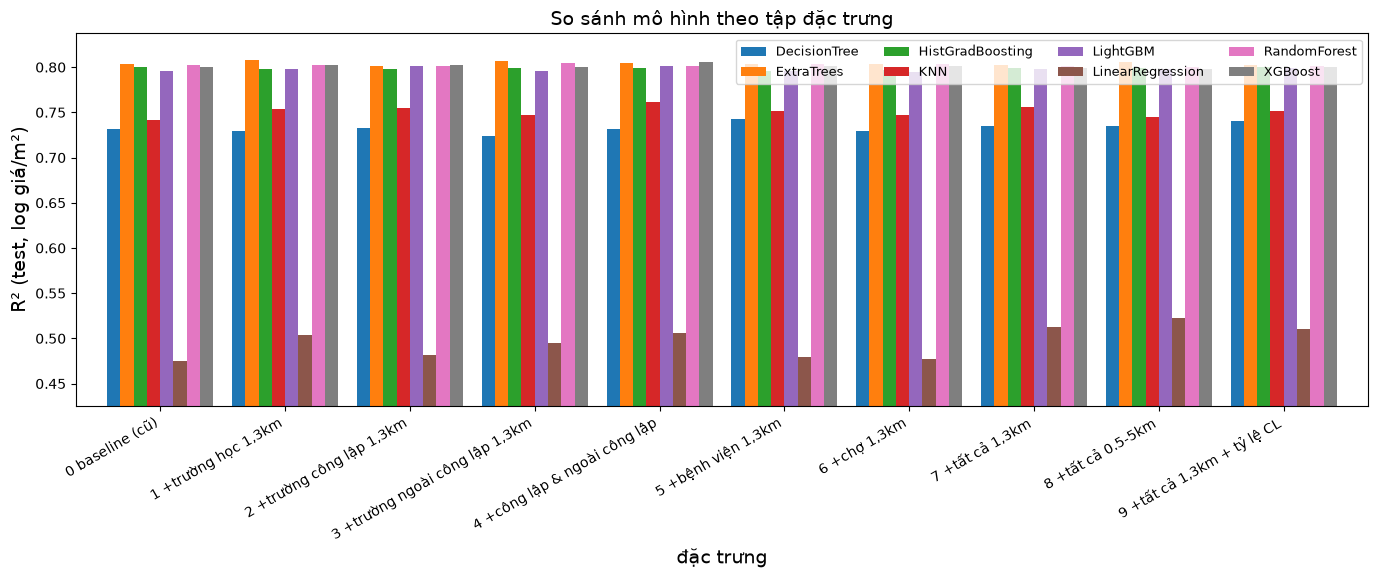

In [134]:
# So sánh với mô hình cũ (baseline) theo từng mô hình: ΔR² khi thêm đặc trưng
base_name = next(iter(FEATURE_SETS))
pivot_r2 = results.pivot(index="đặc trưng", columns="mô hình", values="R²")
pivot_cv = results.pivot(index="đặc trưng", columns="mô hình", values="CV R² (mean)")
print("R² trên test"); display(pivot_r2.round(4))
print("ΔR² so với baseline"); display((pivot_r2 - pivot_r2.loc[base_name]).round(4))
print("CV R² (mean) trên train"); display(pivot_cv.round(4))

# Biểu đồ: R² test của từng mô hình theo tập đặc trưng
ax = pivot_r2.plot(kind="bar", figsize=(14, 6), width=0.85)
ax.set_ylim(max(0, pivot_r2.values.min() - 0.05), pivot_r2.values.max() + 0.03)
ax.set_ylabel("R² (test, log giá/m²)"); ax.set_title("So sánh mô hình theo tập đặc trưng")
plt.xticks(rotation=30, ha="right"); plt.legend(ncol=4, fontsize=9)
save_fig("poi_experiment_r2")
plt.show()

Tốt nhất: ExtraTrees / 1 +trường học 1,3km  R²=0.8074  MAE giá=33.49 tr/m²


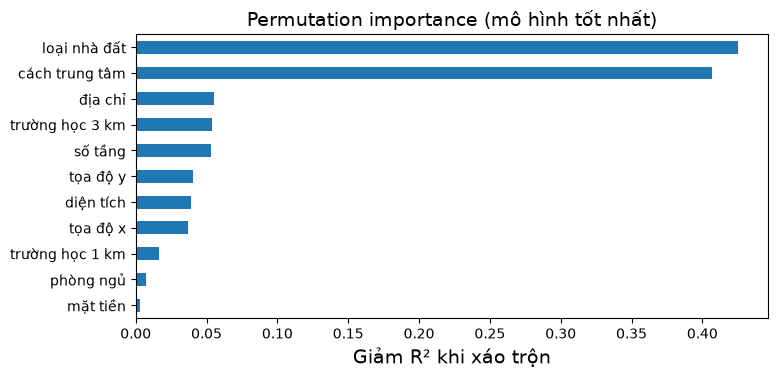

['models_exp/best_poi_experiment.pkl']

In [135]:
# Mô hình tốt nhất + feature importance (permutation trên test, đo bằng mức giảm R²)
from sklearn.inspection import permutation_importance
best = results.iloc[0]
best_cols = FEATURE_SETS[best["đặc trưng"]]
best_pipe = fitted_models[(best["đặc trưng"], best["mô hình"])]
print(f"Tốt nhất: {best['mô hình']} / {best['đặc trưng']}  R²={best['R²']:.4f}  MAE giá={best['MAE giá (tr/m²)']:.2f} tr/m²")

pi = permutation_importance(best_pipe, exp_test[best_cols], y_exp_test, n_repeats=5, random_state=42, n_jobs=-1)
pi_s = pd.Series(pi.importances_mean, index=best_cols).sort_values()
pi_s.plot(kind="barh", figsize=(8, max(4, len(best_cols) * 0.3)))
plt.title("Permutation importance (mô hình tốt nhất)"); plt.xlabel("Giảm R² khi xáo trộn")
save_fig("poi_experiment_importance")
plt.show()

# Lưu mô hình thí nghiệm riêng, không ghi đè các .pkl của mô hình cũ
Path("models_exp").mkdir(exist_ok=True)
jb.dump(best_pipe, "models_exp/best_poi_experiment.pkl")

### Nhận xét: mô hình mới so với mô hình cũ

Số liệu đo ở lần chạy gần nhất (test 20%, target `log(giá/m²)`, CV 5-fold trên train; chạy lại có thể lệch vài phần nghìn):

| | Mô hình cũ (không POI) | Tốt nhất khi thêm POI |
|---|---|---|
| Cây (RF/ExtraTrees/XGB/LightGBM) R² test | 0.796 – 0.803 | **0.807** (ExtraTrees + trường học 1,3 km) |
| MAE giá | ≈ 34.4 tr/m² (RF) | ≈ 33.5 tr/m² (ExtraTrees) |
| MAPE | ≈ 25.4 – 26.5 % | ≈ 25.0 % |
| LinearRegression R² | 0.475 | 0.523 (tất cả POI 0.5–5 km) |
| KNN R² | 0.741 | 0.762 (công lập + ngoài công lập 1,3 km) |

- **Mô hình dạng cây gần như không hưởng lợi**: ΔR² nằm trong ±0.005 và đổi dấu tùy mô hình/tập đặc trưng; chênh lệch CV R² ≤ 0.003, nhỏ hơn độ lệch chuẩn giữa các fold (≈ 0.005 – 0.007) ⇒ phần cải thiện chủ yếu là nhiễu. Lý do hợp lý: tọa độ x, y, quận và khoảng cách trung tâm đã mã hóa phần lớn thông tin vị trí mà số tiện ích xung quanh mang.
- **Mô hình tuyến tính và KNN được lợi rõ** (LinearRegression +0.03 đến +0.05, KNN +0.01 đến +0.02) vì chúng không tự học được tương tác phi tuyến của tọa độ, nên POI bổ sung thông tin vị trí. Hai mô hình này vẫn thấp hơn hẳn các mô hình cây.
- **Nhóm POI**: trường học (và tách công lập / ngoài công lập) có tác động dương nhỏ nhất quán nhất; bệnh viện và chợ gần như không đổi. Bán kính 1 – 3 km là đủ, thêm 0.5 – 5 km không tốt hơn (còn làm LinearRegression/KNN dao động) và đặc trưng tỷ lệ công lập không giúp.
- **Kết luận**: nếu dùng một mô hình cây, thêm `trường học 1,3 km` (hoặc công lập + ngoài công lập 1,3 km) nhiều nhất chỉ tăng ≈ 0.004 R² (≈ 1 tr/m² MAE) – chưa đủ ý nghĩa thống kê so với baseline. Lựa chọn mô hình giữa RF, ExtraTrees, XGBoost, LightGBM mới là yếu tố nhỏ hơn nhiều so với độ nhiễu của dữ liệu (CV R² ≈ 0.81 – 0.82 cho mọi cây). Muốn cải thiện thật nên tập trung vào chất lượng dữ liệu (giá rao, outlier, số tầng/mặt tiền thiếu) hoặc đặc trưng chi tiết hơn (khoảng cách tới tiện ích gần nhất, địa chỉ phường).
- Lưu ý: cột `ownership` của bệnh viện trong DB đang trống nên chưa thể tách bệnh viện công/tư; `bệnh viện` ở đây chỉ lọc `poi_subtype = 'Bệnh viện'`.


## THÍ NGHIỆM LOẠI NHÀ × KHU VỰC

Mục "POI" ở trên cho thấy `loại nhà đất` và `cách trung tâm` quyết định gần hết giá/m². Cả `loại nhà đất` (0–9) lẫn `địa chỉ` (quận, 0–23) đang là **mã số** nhưng không có thứ tự thật, nên mô hình tuyến tính/KNN hiểu sai. Mục này thử ba hướng:

1. **One-hot** `loại nhà đất` và `địa chỉ` (thêm bản one-hot cả cột chéo `loại×quận`).
2. **Target encoding**: thêm đặc trưng "log giá/m² trung bình của nhóm (loại nhà, quận)". Tính **chỉ trên train**, làm mượt (smoothing) về giá trị của loại nhà khi nhóm ít mẫu, và dùng **out-of-fold** cho các dòng train để nhãn của một dòng không lọt vào chính đặc trưng của nó; nằm trong Pipeline nên CV tính lại trong từng fold. Nhóm lạ ở test dùng giá trị toàn cục.
3. **Mô hình riêng cho từng loại nhà** (loại < 300 dòng train dùng mô hình chung) rồi ghép dự đoán.

Cách chạy: sửa `MA_HOA`, `CAU_HINH`, `MODELS_2` (thí nghiệm 1–2) và `MODELS_3`, `MA_HOA_3`, `COLS_3` (thí nghiệm 3), rồi chạy lại ô tương ứng. Cần đã chạy ô định nghĩa `MODELS`/`BASE`/`exp_train` của mục POI. Train/test, imputer median (chỉ từ train) và CV `KFold(5, random_state=42)` giữ nguyên như mục trước.

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer

CAT = ["loại nhà đất", "địa chỉ"]
COT_CHEO = "loại×quận"


class MucGiaNhom(BaseEstimator, TransformerMixin):
    """Target encoding: log(giá/m²) trung bình của nhóm (loại nhà, quận) làm đặc trưng mới.

    che_do: tập con của ("loai", "quan", "loai_quan") -> mỗi phần tử thêm một cột "TE <tên>".
    Chống rò rỉ nhãn bằng hai lớp:
      - làm mượt: (tổng + m·prior) / (n + m); nhóm ít mẫu bị kéo về prior
        (loai, quan -> trung bình toàn cục; loai_quan -> giá trị đã mượt của loại nhà);
      - out-of-fold khi fit_transform: giá trị của mỗi dòng train chỉ tính từ các dòng
        train KHÁC fold, nên nhãn của chính dòng đó không lọt vào đặc trưng của nó.
    transform (test / fold validation) dùng thống kê của toàn bộ phần train; nhóm lạ -> prior.
    """

    def __init__(self, che_do=("loai_quan",), smoothing=20, n_folds=5):
        self.che_do = che_do
        self.smoothing = smoothing
        self.n_folds = n_folds

    def _thong_ke(self, X, y):
        d = pd.DataFrame({"l": X[CAT[0]].to_numpy(), "q": X[CAT[1]].to_numpy(), "y": np.asarray(y, float)})
        m, g = self.smoothing, d["y"].mean()
        muot = lambda s, prior: (s["sum"] + m * prior) / (s["count"] + m)
        agg = lambda keys: d.groupby(keys)["y"].agg(["sum", "count"])
        loai = muot(agg("l"), g)
        quan = muot(agg("q"), g)
        lq = agg(["l", "q"])
        lq = (lq["sum"] + m * loai.reindex(lq.index.get_level_values(0)).to_numpy()) / (lq["count"] + m)
        return g, loai, quan, lq

    def _ma_hoa(self, X, tk):
        g, loai, quan, lq = tk
        l, q = X[CAT[0]], X[CAT[1]]
        enc_l = l.map(loai).fillna(g).to_numpy()
        out = {
            "loai": enc_l,
            "quan": q.map(quan).fillna(g).to_numpy(),
            "loai_quan": lq.reindex(pd.MultiIndex.from_arrays([l, q])).to_numpy(),
        }
        out["loai_quan"] = np.where(np.isnan(out["loai_quan"]), enc_l, out["loai_quan"])
        return {f"TE {k}": out[k] for k in self.che_do}

    def fit(self, X, y):
        self.thong_ke_ = self._thong_ke(X, y)
        return self

    def transform(self, X):
        return X.assign(**self._ma_hoa(X, self.thong_ke_))

    def fit_transform(self, X, y=None):
        y = np.asarray(y, float)
        oof = {f"TE {k}": np.full(len(X), np.nan) for k in self.che_do}
        for tr, va in KFold(self.n_folds, shuffle=True, random_state=42).split(X):
            ma = self._ma_hoa(X.iloc[va], self._thong_ke(X.iloc[tr], y[tr]))
            for k, v in ma.items():
                oof[k][va] = v
        self.fit(X, y)
        return X.assign(**oof)


def them_cot_cheo(X):
    """Cột loại nhà × quận (mã số duy nhất cho từng tổ hợp) để one-hot chéo."""
    return X.assign(**{COT_CHEO: X[CAT[0]] * 100 + X[CAT[1]]})


def xay_pipeline(ten_mo_hinh, cols, ma_hoa="mã số"):
    """Pipeline = [target encoding] -> [cột chéo] -> tiền xử lý (one-hot cho cột phân loại,
    median cho số, scale nếu là Linear/KNN) -> mô hình. Mô hình lấy từ MODELS nên cấu hình khớp
    với mục thí nghiệm POI; chỉ giới hạn n_jobs <= 4.

    ma_hoa: "mã số" (như mô hình cũ) | "one-hot" | "one-hot + chéo" | "TE loại×quận" |
            "TE đủ 3" (loai, quan, loai_quan) | "TE quận" | "TE loại" | "one-hot + TE loại×quận"
    """
    mau = MODELS[ten_mo_hinh]()
    model, scale = mau.named_steps["model"], "scaler" in mau.named_steps
    if "n_jobs" in model.get_params():
        model.set_params(n_jobs=4)
    steps = []
    te = {"TE loại×quận": ("loai_quan",), "TE đủ 3": ("loai", "quan", "loai_quan"),
          "TE quận": ("quan",), "TE loại": ("loai",), "one-hot + TE loại×quận": ("loai_quan",)}.get(ma_hoa)
    if te:
        steps.append(("te", MucGiaNhom(che_do=te)))
    cheo = ma_hoa == "one-hot + chéo"
    if cheo:
        steps.append(("cheo", FunctionTransformer(them_cot_cheo)))
    so = Pipeline([("imputer", SimpleImputer(strategy="median"))] + ([("scaler", StandardScaler())] if scale else []))
    if ma_hoa.startswith("one-hot"):
        phan_loai = r"^(loại nhà đất|địa chỉ|loại×quận)$"
        steps.append(("pre", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), make_column_selector(pattern=phan_loai)),
            ("so", so, make_column_selector(pattern=f"^(?!{phan_loai[1:-1]}$)")),
        ])))
    else:
        steps.append(("pre", so))
    return Pipeline(steps + [("model", model)])


def do_luong(y_log, pred_log):
    """Chỉ số trên log và trên giá thật (triệu/m²)."""
    that, dd = np.exp(y_log), np.exp(pred_log)
    return {"RMSE": np.sqrt(mean_squared_error(y_log, pred_log)), "MAE": mean_absolute_error(y_log, pred_log),
            "R²": r2_score(y_log, pred_log), "MAE giá (tr/m²)": mean_absolute_error(that, dd),
            "MAPE %": (np.abs(dd - that) / that).mean() * 100}


def chay_thi_nghiem_2(cau_hinh, models, X_train, y_train, X_test, y_test, cv=CV_FOLDS):
    """cau_hinh: {tên: (cột, mã hóa)}. CV trên train + chấm trên test cho từng (cấu hình x mô hình).
    Chỉ giữ pipeline có CV R² cao nhất (chọn bằng CV, không nhìn test) để tiết kiệm RAM.
    Trả về (DataFrame kết quả sắp theo R² test, pipeline tốt nhất, nhãn của nó)."""
    kfold = KFold(cv, shuffle=True, random_state=42)
    rows, best = [], (-np.inf, None, None)
    for ten, (cols, ma_hoa) in cau_hinh.items():
        for m_name in models:
            pipe = xay_pipeline(m_name, cols, ma_hoa)
            cv_r2 = cross_val_score(pipe, X_train[cols], y_train, cv=kfold, scoring="r2")
            pipe.fit(X_train[cols], y_train)
            rows.append({"cấu hình": ten, "mô hình": m_name, "số đặc trưng": len(cols),
                         "CV R² (mean)": cv_r2.mean(), "CV R² (std)": cv_r2.std(),
                         **do_luong(y_test, pipe.predict(X_test[cols]))})
            if cv_r2.mean() > best[0]:
                best = (cv_r2.mean(), pipe, f"{m_name} / {ten}")
    return pd.DataFrame(rows).sort_values("R²", ascending=False).reset_index(drop=True), best[1], best[2]

### Thí nghiệm 1 + 2: one-hot và target encoding

Mỗi cấu hình = (cột, cách mã hóa) chạy với cả 8 mô hình, có/không bộ POI tốt nhất (trường học 1 km + 3 km). Baseline để so sánh: `mã số | không POI` (đúng mô hình cũ).

In [ ]:
# ====== SỬA Ở ĐÂY ĐỂ THÍ NGHIỆM ======
POI_TOT = poi(["trường học"])  # bộ POI tốt nhất ở mục trước: trường học 1 km + 3 km
MA_HOA = ["mã số", "one-hot", "one-hot + chéo", "TE loại×quận", "TE đủ 3", "one-hot + TE loại×quận"]
CAU_HINH = {f"{ma} | {'POI' if co_poi else 'không POI'}": (BASE + (POI_TOT if co_poi else []), ma)
            for ma in MA_HOA for co_poi in (False, True)}
# ablation target encoding (chỉ quận / chỉ loại), không POI
CAU_HINH.update({f"{ma} | không POI": (BASE, ma) for ma in ["TE quận", "TE loại"]})
MODELS_2 = list(MODELS)  # tất cả mô hình của mục trước
# =====================================

results2, best2_pipe, best2_nhan = chay_thi_nghiem_2(CAU_HINH, MODELS_2, exp_train, y_exp_train, exp_test, y_exp_test)
print("Tốt nhất theo CV:", best2_nhan)
results2.round(4)

In [ ]:
# ΔR² so với mô hình cũ (mã số, không POI) theo từng mô hình, trên test và trên CV
base2 = "mã số | không POI"
r2_test = results2.pivot(index="cấu hình", columns="mô hình", values="R²")
r2_cv = results2.pivot(index="cấu hình", columns="mô hình", values="CV R² (mean)")
print("ΔR² trên test so với baseline (mã số, không POI)"); display((r2_test - r2_test.loc[base2]).round(4))
print("ΔCV R² so với baseline (độ lệch chuẩn giữa các fold ≈ 0.005 – 0.007)"); display((r2_cv - r2_cv.loc[base2]).round(4))

import seaborn as sns
fig, axs = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, (ten, bang) in zip(axs, (("test", r2_test), ("CV 5-fold (train)", r2_cv))):
    sns.heatmap(bang - bang.loc[base2], annot=True, fmt=".3f", cmap="RdYlGn", center=0, vmin=-0.03, vmax=0.03, cbar=False, ax=ax)
    ax.set_title(f"ΔR² ({ten}) so với baseline"); ax.set_ylabel("")
plt.tight_layout(); save_fig("loai_khuvuc_delta_r2"); plt.show()
print("(Linear/KNN vượt thang ±0.03 nên màu bão hòa; xem số trong bảng ở trên)")

Path("models_exp").mkdir(exist_ok=True)
jb.dump(best2_pipe, "models_exp/best_loai_khuvuc.pkl")  # mô hình tốt nhất theo CV, không ghi đè .pkl cũ

### Nhận xét thí nghiệm 1 + 2

Số đo ở lần chạy gần nhất (test 20%, target `log(giá/m²)`; CV 5-fold trên train có độ lệch chuẩn giữa các fold ≈ 0.005 – 0.007):

| Mô hình | Baseline (mã số, không POI) | Tốt nhất với cách mã hóa mới | Δ |
|---|---|---|---|
| LinearRegression R² test | 0.475 | **0.750** (one-hot + chéo, có POI) | **+0.275** |
| KNN R² test | 0.741 | 0.775 (TE đủ 3, có POI) | +0.034 |
| ExtraTrees R² test | 0.803 | 0.810 (TE đủ 3, có POI) | +0.007 |
| RandomForest / XGBoost / LightGBM / HistGB R² test | 0.803 / 0.799 / 0.796 / 0.800 | ≤ +0.010 ở mọi cấu hình, nhiều cấu hình còn âm (tới -0.009) | trong nhiễu |

- **Mô hình tuyến tính được lợi rất lớn**: chỉ cần one-hot là R² 0.475 → 0.726; thêm cột chéo `loại×quận` → 0.749. Target encoding loại×quận cho 0.732, gần ngang one-hot. Đây là lỗi biểu diễn (mã số bị coi như thứ tự) chứ không phải thông tin mới. Ablation: TE chỉ theo loại nhà cho Linear 0.679, chỉ theo quận 0.532 ⇒ phần lớn sức mạnh đến từ **loại nhà**.
- **KNN cũng được lợi vừa** (+0.01 đến +0.03), nhờ khoảng cách không còn bị méo bởi mã số.
- **Các mô hình cây không hưởng lợi**: chênh lệch R² test từ -0.009 đến +0.010, chênh lệch CV từ -0.007 đến +0.004, đều nằm trong độ lệch chuẩn giữa các fold. Cây tự tách được `loại nhà đất` và `địa chỉ` từ mã số nên mã hóa lại không thêm gì; target encoding và one-hot chéo thậm chí không hơn baseline trong CV.
- **Mô hình "tốt nhất" không ổn định theo tiêu chí**: theo test là ExtraTrees + TE đủ 3 + POI (R² 0.8104, MAE giá 33.8 tr/m², MAPE 24.8 %); theo CV là XGBoost + one-hot, không POI (CV 0.826 so với 0.823 của baseline XGBoost). So với mô hình POI cũ (ExtraTrees + trường học 1,3 km, mã số: R² 0.8074, MAE 33.5, MAPE 24.95 %) thì cải thiện ≈ +0.003 R², MAE giá thậm chí xấu hơn một chút ⇒ **không có ý nghĩa thống kê**.
- Kết luận: với mô hình cây đang dùng, đừng đổi cách mã hóa; **với LinearRegression/KNN thì bắt buộc dùng one-hot** (hoặc one-hot + chéo). Tương tác loại nhà × khu vực không cho cây thêm gì vì chúng đã học được tương tác này.

### Thí nghiệm 3: mô hình riêng cho từng loại nhà

Loại nhà trong train: căn hộ chung cư 1870, nhà riêng 3627, biệt thự/liền kề 550, nhà mặt phố 1600, bán đất 1012 dòng (đều ≥ 300 nên mỗi loại có mô hình riêng; loại lạ ở test, nếu có, dùng mô hình chung). So **cùng thuật toán, cùng đặc trưng (BASE + trường học 1,3 km), cùng mã hóa**: một mô hình chung vs 5 mô hình riêng.

In [ ]:
from functools import partial

LOAI_TEN = {0: "căn hộ chung cư", 2: "nhà riêng", 3: "biệt thự, liền kề", 4: "nhà mặt phố", 7: "bán đất"}


class MoHinhTheoLoai(BaseEstimator, RegressorMixin):
    """Mỗi loại nhà có một mô hình riêng; loại có ít hơn `min_n` dòng train (hoặc loại lạ ở test)
    dùng mô hình chung huấn luyện trên toàn bộ train. make_model() trả về estimator chưa fit."""

    def __init__(self, make_model, cot="loại nhà đất", min_n=300):
        self.make_model = make_model
        self.cot = cot
        self.min_n = min_n

    def fit(self, X, y):
        y, loai = np.asarray(y), X[self.cot].to_numpy()
        self.chung_ = self.make_model().fit(X, y)
        self.rieng_ = {l: self.make_model().fit(X[loai == l], y[loai == l])
                       for l in np.unique(loai) if (loai == l).sum() >= self.min_n}
        return self

    def predict(self, X):
        pred, loai = self.chung_.predict(X), X[self.cot].to_numpy()
        for l, mo_hinh in self.rieng_.items():
            if (loai == l).any():
                pred[loai == l] = mo_hinh.predict(X[loai == l])
        return pred


def chay_theo_loai(ten_mo_hinh, cols, ma_hoa_list, X_train, y_train, X_test, y_test, cv=CV_FOLDS):
    """So mô hình chung với mô hình riêng theo loại nhà (cùng thuật toán, cùng đặc trưng, cùng mã hóa).
    Trả về (bảng tổng, dict dự đoán test trên log giá)."""
    kfold = KFold(cv, shuffle=True, random_state=42)
    rows, preds = [], {}
    for m in ten_mo_hinh:
        for ma in ma_hoa_list:
            make = partial(xay_pipeline, m, cols, ma)
            for kieu, est in (("chung", make()), ("riêng theo loại", MoHinhTheoLoai(make))):
                cv_r2 = cross_val_score(est, X_train[cols], y_train, cv=kfold, scoring="r2")
                est.fit(X_train[cols], y_train)
                preds[(m, ma, kieu)] = est.predict(X_test[cols])
                rows.append({"mô hình": m, "mã hóa": ma, "kiểu": kieu, "CV R² (mean)": cv_r2.mean(),
                             "CV R² (std)": cv_r2.std(), **do_luong(y_test, preds[(m, ma, kieu)])})
    return pd.DataFrame(rows).sort_values("R²", ascending=False).reset_index(drop=True), preds


def bang_theo_loai(preds, key_chung, key_rieng, X_test, y_test):
    """R²/MAE/MAPE trên test của từng loại nhà: mô hình chung và mô hình riêng."""
    rows = []
    for l, ten in LOAI_TEN.items():
        mask = (X_test["loại nhà đất"] == l).to_numpy()
        for kieu, key in (("chung", key_chung), ("riêng theo loại", key_rieng)):
            rows.append({"loại nhà": ten, "số tin test": int(mask.sum()), "kiểu": kieu,
                         **do_luong(np.asarray(y_test)[mask], preds[key][mask])})
    return pd.DataFrame(rows)

In [ ]:
# ====== SỬA Ở ĐÂY ĐỂ THÍ NGHIỆM ======
MODELS_3 = ["RandomForest", "ExtraTrees", "HistGradBoosting", "XGBoost", "LightGBM"]
MA_HOA_3 = ["mã số", "one-hot"]
COLS_3 = BASE + POI_TOT
# =====================================

results3, preds3 = chay_theo_loai(MODELS_3, COLS_3, MA_HOA_3, exp_train, y_exp_train, exp_test, y_exp_test)
results3.round(4)

In [ ]:
# Bảng theo từng loại nhà cho mô hình tốt nhất theo CV (chung vs riêng)
g = results3.sort_values("CV R² (mean)", ascending=False).iloc[0]
tl = bang_theo_loai(preds3, (g["mô hình"], g["mã hóa"], "chung"), (g["mô hình"], g["mã hóa"], "riêng theo loại"), exp_test, y_exp_test)
print(f"{g['mô hình']} / {g['mã hóa']}"); display(tl.round(3))

ax = tl.pivot(index="loại nhà", columns="kiểu", values="MAPE %").plot(kind="barh", figsize=(8, 4))
ax.set_xlabel("MAPE % trên test"); ax.set_title(f"{g['mô hình']} ({g['mã hóa']}): mô hình chung vs riêng theo loại")
save_fig("loai_khuvuc_theo_loai"); plt.show()

# Chênh lệch CV R² khi tách theo loại nhà (riêng - chung), theo từng mô hình/mã hóa
dcv = results3.pivot_table(index=["mô hình", "mã hóa"], columns="kiểu", values="CV R² (mean)")
dcv["riêng - chung"] = dcv["riêng theo loại"] - dcv["chung"]
display(dcv.round(4))

### Nhận xét thí nghiệm 3

- **Tổng thể không có lợi**: CV R² (riêng − chung) là XGBoost -0.008 đến -0.010, LightGBM -0.013 đến -0.014, HistGB -0.013 đến -0.014, RandomForest +0.004 (mã số) và -0.000 (one-hot), ExtraTrees -0.001 đến -0.004. Trên test, ExtraTrees chung 0.8095 vs riêng 0.8061 (one-hot), XGBoost chung 0.7975 vs riêng 0.8008 nhưng CV lại ngược chiều ⇒ nhiễu. Lý do hợp lý: mỗi mô hình riêng chỉ còn 550 – 3600 dòng nên phương sai tăng, trong khi mô hình chung đã dùng `loại nhà đất` để chia nhánh.
- **Theo từng loại (XGBoost + one-hot, test)**: căn hộ chung cư R² 0.818 → 0.837, MAPE 15.3 → 14.1 %; bán đất MAPE 68.8 → 63.8 %; nhà mặt phố 26.0 → 25.8 %; trong khi nhà riêng R² 0.707 → 0.685 và biệt thự 0.660 → 0.598 (chỉ 155 tin test) bị xấu đi. Với ExtraTrees + mã số thì căn hộ chỉ 0.833 → 0.838. Cải thiện ở căn hộ không nhất quán giữa các thuật toán nên chưa đủ để kết luận.
- **Nhóm khó nhất là bán đất**: MAPE 58 – 69 % (R² ≈ 0.70 – 0.75) so với 14 – 15 % của căn hộ. Đây mới là nơi sai số lớn: giá đất rao có độ nhiễu cao (mặt tiền, hẻm, quy hoạch) mà các cột hiện có không mô tả được.

### Kết luận chung so với mô hình cũ

| | Mô hình cũ (RF, mã số, không POI) | Tốt nhất mục này |
|---|---|---|
| Cây (R² test) | 0.803 | 0.810 (ExtraTrees + TE đủ 3 + POI), nhưng ở mức nhiễu |
| LinearRegression R² test | 0.475 | 0.750 (one-hot + chéo + POI) |
| KNN R² test | 0.741 | 0.775 |

Không nên chuyển sang mô hình theo loại nhà hay target encoding cho mô hình cây: cải thiện (≤ 0.007 R²) nhỏ hơn độ lệch chuẩn CV. Nếu cần một mô hình tuyến tính/KNN (để giải thích hoặc chạy nhẹ) thì phải one-hot. Muốn cải thiện thật cần thêm thông tin mới, nhất là cho nhóm bán đất (mặt tiền, hẻm, hướng, phường) thay vì đổi cách mã hóa các cột sẵn có.